# SafeGuard KWS v2: Bilingual Emergency Keyword Spotting (Kiswahili + English)

**Goal:** detect distress words on a tiny wearable (ESP32-C3) in two languages, with a design that stays safe against false alarms.

| | |
|---|---|
| **Keywords** | `msaada`, `polisi` (Kiswahili) · `help`, `police` (English) |
| **Other classes** | `unknown` (ordinary speech in both languages) · `noise` (environmental sounds) |
| **Safety design** | A single word never raises an alert on its own. The *trigger rule* needs **two keyword detections within a few seconds** (same word repeated, or two different keywords), followed by a **cancel window** on the device. |
| **Data** | Real multi-speaker speech only: Mozilla Common Voice Swahili (word-cut by forced alignment), Multilingual Spoken Words Corpus (English), ESC-50 (noise). No text-to-speech. |
| **Models** | Baselines (majority class, MFCC + Logistic Regression, MFCC + Random Forest) → DS-CNN (TinyML) with hyper-parameter search + ablations → INT8 TFLite → **Edge Impulse** track for ESP32 deployment |

**Notebook map**
0. Setup & configuration  ·  1. Data acquisition  ·  2. Manifest, QC & speaker-disjoint split  ·  3. Exploratory data analysis  ·  4. Preprocessing & augmentation  ·  5. Baselines  ·  6. DS-CNN model  ·  7. Hyper-parameter search & ablations  ·  8. Final training  ·  9. Evaluation (classification, per-language, robustness, streaming trigger simulation)  ·  10. Quantisation & export  ·  11. Edge Impulse track  ·  12. Summary & model card

**Dry run:** set `SMOKE_TEST = True` in the config cell to run the *whole* notebook on a tiny synthetic dataset in a few minutes. This checks your environment before you spend hours downloading real data. Set it back to `False` for the real run.

**Secrets (never paste keys into cells or chat):** Colab ▸ 🔑 Secrets: `MDC_API_KEY` (Mozilla Data Collective) and `EI_API_KEY` (Edge Impulse project key).

## 0. Setup & configuration

In [ ]:
# Colab already ships TensorFlow. `datasets<4` is pinned because the English keyword corpus (MSWC) is a script-based dataset.
!pip install -q -U "datasets<4" datacollective librosa soundfile scikit-learn seaborn tqdm requests

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.


In [ ]:
import os, sys, re, io, gc, json, math, time, random, hashlib, tarfile, zipfile, csv, warnings, shutil
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import soundfile as sf
import librosa
from tqdm.auto import tqdm
import tensorflow as tf

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

# ----------------------------- RUN MODE -----------------------------
SMOKE_TEST    = False   # True = tiny synthetic dataset, 1-2 epochs (checks the notebook runs end-to-end)
FORCE_REBUILD = False   # True = redo data acquisition even if cached manifests exist

# ----------------------------- TASK ---------------------------------
SW_WORDS = ["msaada", "polisi"]
EN_WORDS = ["help", "police"]
TARGETS  = SW_WORDS + EN_WORDS
LABELS   = TARGETS + ["unknown", "noise"]
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
NUM_CLASSES = len(LABELS)
LANG_OF  = {"msaada": "sw", "polisi": "sw", "help": "en", "police": "en"}
SR = 16000                   # sample rate
WIN = SR                     # 1.0 s analysis window

# Words that sound/look similar to the keywords (hard negatives). Used only if they occur in the data.
SW_NEAR = ["pole", "polepole", "msaidizi", "saidia", "nisaidie", "tuma", "piga", "ita", "simu", "sauti", "pesa"]
EN_NEAR = ["hello", "held", "hell", "hold", "helps", "helped", "helping", "policy", "polite", "please", "pole", "palace", "call", "send"]

# Trigger rule (used in the streaming simulation and exported to firmware)
PAIR_WINDOW_S  = 4.0         # two detections must fall within this many seconds
REFRACTORY_S   = 0.6         # ignore re-detections of the same utterance
COOLDOWN_S     = 10.0        # after an alert, stay quiet for this long
HOP_S          = 0.25        # inference stride on the device

# ----------------------------- MCU BUDGET (ESP32-C3 Super Mini) -----
# Chip: single-core RISC-V @160 MHz, 400 KB SRAM shared with Wi-Fi/BLE stack + audio buffers + firmware, no PSRAM, no FPU/vector unit.
# These limits are ENGINEERING CHOICES for a wearable; change them if your firmware leaves more or less room.
MCU = dict(
    flash_model_kb = 200,     # flash you are willing to give the model (boards usually have 4 MB shared with firmware)
    arena_kb       = 64,      # tensor arena; keep well under the 400 KB total SRAM
    params_max     = 40_000,
    macs_max       = 3_000_000,
    macs_per_sec   = 10e6,    # ASSUMPTION for scalar INT8 on a 160 MHz RISC-V core. CALIBRATE with a real on-device timing.
    latency_ms_max = 150,     # one inference must finish well inside the 250 ms hop (features need time too)
)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

# ----------------------------- STORAGE -------------------------------
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/SafeGuard-STT")
    LOCAL = Path("/content")
except Exception:
    BASE = Path("./SafeGuard-STT"); LOCAL = Path(".")
ROOT   = BASE / ("kws_v2_smoke" if SMOKE_TEST else "kws_v2")
CLIPS  = ROOT / "clips"                 # clips/<label>/*.wav  (1 s, 16 kHz, mono, int16)
RES    = ROOT / "results"
SW_CACHE = BASE / "kws_sw"              # re-uses validated.tsv + raw clips from your earlier run
for d in (ROOT, CLIPS, RES, SW_CACHE):
    d.mkdir(parents=True, exist_ok=True)

# ----------------------------- DATA SOURCES --------------------------
CV_DATASET_ID = "cmu5sgles002zo1071nphgtby"   # Common Voice Scripted Speech 27.0 - Swahili
CV_DOWNLOAD_DIR = LOCAL / "cv_download"       # local disk (the archive is ~21 GB; free Drive is 15 GB)
CORPUS_PATH = None                            # set to an already-downloaded folder / .tar.gz to skip downloading

def get_secret(name, prompt=False):
    if os.environ.get(name):
        return os.environ[name]
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v:
            os.environ[name] = v
            return v
    except Exception:
        pass
    if prompt:
        from getpass import getpass
        os.environ[name] = getpass(f"{name} (hidden): ")
        return os.environ[name]
    return None

print("TensorFlow", tf.__version__, "| GPU:", [d.name for d in tf.config.list_physical_devices("GPU")] or "none")
print("Workspace:", ROOT, "| SMOKE_TEST =", SMOKE_TEST)

Mounted at /content/drive
TensorFlow 2.21.0 | GPU: none
Workspace: /content/drive/MyDrive/SafeGuard-STT/kws_v2 | SMOKE_TEST = False


### Data sources and licences

| Source | Used for | Licence / terms |
|---|---|---|
| Mozilla Common Voice 27.0 Swahili | `msaada`, `polisi`, Swahili `unknown` | CC0. **Do not re-host or re-share the dataset; do not try to identify speakers.** Clips here stay in your private Drive. |
| Multilingual Spoken Words Corpus (MSWC) | `help`, `police`, English `unknown` | CC-BY 4.0 (attribution required) |
| ESC-50 | `noise` | Dataset is **CC BY-NC** (non-commercial); fine for a university project, check before commercial use |
| Your own recordings (later) | **test-only** real-device evaluation | yours |

Speaker ids are the datasets' own anonymous hashes. They are used **only** to keep each speaker in a single split.

### Target hardware: ESP32-C3 Super Mini (not a phone)
This notebook trains a **TinyML** model for a microcontroller. A phone could run a far larger model (or a full speech recogniser), the ESP32-C3 cannot.

What constrains the design:
- **~400 KB SRAM total**, shared with Wi-Fi/BLE, the audio buffer and your firmware, and **no PSRAM**. The tensor arena must stay small (budget above: 64 KB).
- **No FPU and no vector instructions**: INT8 maths runs on scalar instructions, so inference is much slower than on the ESP32-S3. Keep multiply-accumulates (MACs) low.
- **Features cost time too:** a 512-point FFT per frame is expensive without an FPU. This notebook uses a 20 ms hop (49 frames per second of audio instead of 98) and the firmware should *reuse* previous frames when the window slides (Edge Impulse's continuous mode does this).
- **Microphone:** the Super Mini has none; use an I2S MEMS microphone (e.g. INMP441 class).
- **Battery:** gate the classifier with a cheap loudness check so it only runs when there is sound.

Every model in the search is **checked against this budget before training** (parameters, MACs, arena, estimated latency), and over-budget candidates are rejected.

## 1. Data acquisition

Every clip ends up as **1.0 s, 16 kHz, mono, 16-bit WAV** in `clips/<label>/`, with one row in a manifest:
`file, label, lang, speaker, source, word, align_score, forced_split`.

**Why 1-second windows centred on the word, not tight crops?** If keyword clips were tight crops (0.4 s) and `unknown` clips were longer, a model could learn *clip length* instead of the word. Here every class gets the same kind of window: 1 s of real audio centred on the word, with whatever surrounding sound was in the recording. This also matches what the device sees at inference time.

In [ ]:
# ---------------- shared audio helpers ----------------
def peak_norm(x, peak=0.9):
    m = float(np.max(np.abs(x))) if len(x) else 0.0
    return (x / m * peak).astype(np.float32) if m > 1e-6 else x.astype(np.float32)

def fix_len(x, n=WIN):
    """Centre-pad with zeros or centre-crop to exactly n samples."""
    if len(x) >= n:
        a = (len(x) - n) // 2
        return x[a:a + n]
    p = n - len(x)
    return np.pad(x, (p // 2, p - p // 2))

def window_around(wav, start_s, end_s):
    """1 s window of the ORIGINAL recording centred on [start_s, end_s] (zero-pad only at recording edges)."""
    c = int((start_s + end_s) / 2 * SR)
    a, b = c - WIN // 2, c - WIN // 2 + WIN
    left, right = max(0, -a), max(0, b - len(wav))
    seg = wav[max(0, a):min(len(wav), b)]
    return np.pad(seg, (left, right))

def save_clip(label, stem, x, norm=True):
    d = CLIPS / label
    d.mkdir(parents=True, exist_ok=True)
    rel = f"{label}/{stem}.wav"
    sf.write(CLIPS / rel, peak_norm(x) if norm else np.clip(x, -1, 1), SR, subtype="PCM_16")
    return rel

def normalize_words(sentence):
    s = str(sentence).lower().replace("\u2019", "'")
    s = re.sub(r"[^a-z' ]", " ", s)
    return [w.strip("'") for w in s.split() if w.strip("'")]

MANIFEST_COLS = ["file", "label", "lang", "speaker", "source", "word", "align_score", "forced_split", "extra"]
def rows_to_df(rows):
    return pd.DataFrame(rows, columns=MANIFEST_COLS)

### 1a. Kiswahili from Common Voice (forced alignment → word windows)
Reads `validated.tsv`, finds every occurrence of `msaada` and `polisi`, aligns the sentence with the multilingual MMS aligner, and cuts a 1 s window around each word. `unknown` windows come from sentences that **do not** contain a keyword, plus extra near-miss words when they exist. A per-speaker cap stops a few prolific speakers from dominating.

In [ ]:
# ---------------- Common Voice access / archive helpers ----------------
def download_cv():
    key = get_secret("MDC_API_KEY", prompt=True)
    import datacollective as dc
    fn = getattr(dc, "download_dataset", None) or getattr(dc, "save_dataset_to_disk")
    CV_DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
    print("Downloading Common Voice archive (~21 GB). Keep this tab open; interrupted downloads resume if you re-run.")
    try:
        try:
            return Path(fn(CV_DATASET_ID, download_directory=str(CV_DOWNLOAD_DIR)))
        except TypeError:
            return Path(fn(CV_DATASET_ID))
    except PermissionError as e:
        raise RuntimeError(f"{e}\n\nAccept the dataset terms on its page (same account as the API key) and retry.") from e

def resolve_corpus():
    if CORPUS_PATH:
        return Path(CORPUS_PATH)
    marker = SW_CACHE / "corpus_path.txt"
    if marker.exists() and Path(marker.read_text().strip()).exists():
        return Path(marker.read_text().strip())
    p = download_cv()
    marker.write_text(str(p))
    return p

def load_validated_tsv(corpus=None):
    cache = SW_CACHE / "validated.tsv"
    if not cache.exists():
        corpus = corpus or resolve_corpus()
        if corpus.is_dir():
            found = list(corpus.rglob("validated.tsv"))
            if not found:
                raise RuntimeError(f"No validated.tsv under {corpus}")
            cache.write_bytes(found[0].read_bytes())
        else:
            print("Streaming archive for validated.tsv (one pass) ...")
            with tarfile.open(corpus, "r|*") as tar:
                for m in tar:
                    if m.isfile() and m.name.endswith("/validated.tsv"):
                        cache.write_bytes(tar.extractfile(m).read()); break
                else:
                    raise RuntimeError("validated.tsv not found in archive")
    df = pd.read_csv(cache, sep="\t", quoting=csv.QUOTE_NONE, dtype=str,
                     usecols=["client_id", "path", "sentence"], on_bad_lines="skip")
    df = df.dropna(subset=["sentence", "path"]).reset_index(drop=True)
    df["words"] = df["sentence"].map(normalize_words)
    df["speaker"] = "sw_" + df["client_id"].str[:12]
    return df

def collect_clip_files(corpus, wanted):
    """{basename: Path}. Uses already-cached raw clips first; streams the archive only for the missing ones."""
    raw = SW_CACHE / "raw_clips"; raw.mkdir(exist_ok=True)
    found = {b: raw / b for b in wanted if (raw / b).exists()}
    missing = set(wanted) - set(found)
    print(f"raw clips cached: {len(found)} | still to pull: {len(missing)}")
    if not missing:
        return found
    if corpus.is_dir():
        clips_dir = next((p for p in corpus.rglob("clips") if p.is_dir()), None)
        for b in list(missing):
            if clips_dir and (clips_dir / b).exists():
                found[b] = clips_dir / b
        return found
    with tarfile.open(corpus, "r|*") as tar:
        for m in tqdm(tar, desc="scanning archive", unit="file"):
            if not m.isfile():
                continue
            b = os.path.basename(m.name)
            if b in missing:
                (raw / b).write_bytes(tar.extractfile(m).read())
                found[b] = raw / b; missing.discard(b)
                if not missing:
                    break
    return found

class Aligner:
    """Word-level forced alignment with torchaudio's multilingual MMS_FA bundle."""
    def __init__(self):
        import torch, torchaudio
        self.torch = torch
        self.dev = "cuda" if torch.cuda.is_available() else "cpu"
        b = torchaudio.pipelines.MMS_FA
        self.model = b.get_model(with_star=False).to(self.dev).eval()
        self.tok, self.al = b.get_tokenizer(), b.get_aligner()
    def spans(self, wav, words):
        torch = self.torch
        x = torch.from_numpy(wav).float().unsqueeze(0).to(self.dev)
        try:
            with torch.inference_mode():
                em, _ = self.model(x)
                sp = self.al(em[0], self.tok(words))
        except Exception as e:
            return None
        r = x.size(1) / em.size(1) / SR
        return [(w[0].start * r, w[-1].end * r, float(sum(t.score for t in w) / len(w))) for w in sp]

In [ ]:
def build_swahili(max_per_word=800, max_per_speaker=6, unknown_sentences=3500, near_cap=30, min_score=0.35):
    out_csv = ROOT / "manifest_sw.csv"
    if out_csv.exists() and not FORCE_REBUILD:
        print("cached:", out_csv); return pd.read_csv(out_csv)
    rng = random.Random(SEED)
    df = load_validated_tsv()
    print(f"validated sentences: {len(df):,} | speakers: {df.speaker.nunique():,}")

    # ---- candidate selection ----
    pos, near = [], []
    for idx, ws in enumerate(df["words"]):
        for i, w in enumerate(ws):
            if w in SW_WORDS: pos.append((idx, w, i))
            elif w in SW_NEAR: near.append((idx, w, i))
    rng.shuffle(pos); rng.shuffle(near)

    def cap(cands, per_word, per_spk):
        cw, cs, keep = Counter(), Counter(), []
        for idx, w, i in cands:
            s = df.speaker[idx]
            if cw[w] >= per_word or cs[(s, w)] >= per_spk: continue
            cw[w] += 1; cs[(s, w)] += 1; keep.append((idx, w, i))
        return keep
    pos  = cap(pos,  max_per_word, max_per_speaker)
    near = cap(near, near_cap, 2)
    kw_set = set(SW_WORDS) | set(SW_NEAR)
    neutral = df[~df["words"].map(lambda ws: any(w in kw_set for w in ws))]
    neutral = neutral[neutral["words"].map(len).between(3, 14)].sample(
        n=min(unknown_sentences, len(neutral)), random_state=SEED)
    print(f"positives: {Counter(w for _, w, _ in pos)} | near-miss: {len(near)} | neutral sentences: {len(neutral)}")

    wanted = {df.path[i] for i, _, _ in pos + near} | set(neutral.path)
    files = collect_clip_files(resolve_corpus(), wanted)
    aligner = Aligner()
    rows, cache = [], {}

    def get(idx):
        p = df.path[idx]
        if p in cache: return cache[p]
        f = files.get(p)
        if f is None: return None
        wav, _ = librosa.load(str(f), sr=SR, mono=True)
        res = (wav, aligner.spans(wav, df.words[idx]))
        cache[p] = res
        if len(cache) > 40: cache.pop(next(iter(cache)))
        return res

    def emit(idx, i, label, source):
        r = get(idx)
        if not r or not r[1]: return
        wav, sp = r
        s, e, sc = sp[i]
        if sc < min_score or not (0.12 <= e - s <= 1.0): return
        stem = f"{df.speaker[idx]}_{Path(df.path[idx]).stem}_{i}"
        rel = save_clip(label, stem, window_around(wav, s, e))
        rows.append(dict(file=rel, label=label, lang="sw", speaker=df.speaker[idx], source=source,
                         word=df.words[idx][i], align_score=round(sc, 3), forced_split=None, extra=""))

    for idx, w, i in tqdm(pos, desc="keywords"):   emit(idx, i, w, "cv27")
    for idx, w, i in tqdm(near, desc="near-miss"):  emit(idx, i, "unknown", "cv27_near")
    for idx in tqdm(neutral.index, desc="unknown"):
        n = len(df.words[idx]); emit(idx, rng.randrange(n), "unknown", "cv27")
    out = rows_to_df(rows); out.to_csv(out_csv, index=False)
    print(out.label.value_counts().to_string())
    return out

In [ ]:
if SMOKE_TEST:
    print("SMOKE_TEST: skipping Common Voice")
    M_sw = None
else:
    M_sw = build_swahili()
M_sw if M_sw is None else M_sw.groupby(["label", "source"]).size()

validated sentences: 269,140 | speakers: 1,206
positives: Counter({'msaada': 317, 'polisi': 269}) | near-miss: 216 | neutral sentences: 3500
█████████████████████████████████████████████████🦊 100.0% (20.9 GB/20.9 GB) Average: 63.4 MB/s Total time: 05:37
raw clips cached: 4292 | still to pull: 0
Downloading: "https://dl.fbaipublicfiles.com/mms/torchaudio/ctc_alignment_mling_uroman/model.pt" to /root/.cache/torch/hub/checkpoints/model.pt


100%|██████████| 1.18G/1.18G [00:07<00:00, 165MB/s] 


keywords:   0%|          | 0/586 [00:00<?, ?it/s]

near-miss:   0%|          | 0/216 [00:00<?, ?it/s]

unknown:   0%|          | 0/3500 [00:00<?, ?it/s]

label
unknown    3070
msaada      317
polisi      268


label    source   
msaada   cv27          317
polisi   cv27          268
unknown  cv27         2855
         cv27_near     215
dtype: int64

### 1b. English from the Multilingual Spoken Words Corpus
MSWC is Common Voice English already cut into 1-second word clips by forced alignment, so we only **stream** the words we need (no 26 GB download). The stream is scanned until the quotas are filled. `unknown` is capped *per word* so it covers many different words rather than a few.

> If streaming fails (dataset scripts are blocked in some environments), put your own English clips in `real/<label>/…` or `manual_en/<label>/…` (see 1d) and continue; the rest of the notebook is unchanged.

In [ ]:
def build_english(per_keyword=700, per_speaker=6, unknown_n=3500, per_unknown_kw=20, max_scan=900_000):
    out_csv = ROOT / "manifest_en.csv"
    if out_csv.exists() and not FORCE_REBUILD:
        print("cached:", out_csv); return pd.read_csv(out_csv)
    from datasets import load_dataset
    rows, counts, per_spk, unk_kw = [], Counter(), Counter(), Counter()
    scanned = 0
    pbar = tqdm(total=per_keyword * len(EN_WORDS) + unknown_n, desc="MSWC English")
    done = lambda: all(counts[w] >= per_keyword for w in EN_WORDS) and counts["unknown"] >= unknown_n
    try:
        for split in ["validation", "test", "train"]:
            if done() or scanned >= max_scan: break
            ds = load_dataset("MLCommons/ml_spoken_words", languages=["en"], split=split,
                              streaming=True, trust_remote_code=True)
            ds = ds.shuffle(seed=SEED, buffer_size=5000)
            for ex in ds:
                scanned += 1
                if done() or scanned >= max_scan: break
                if ex.get("is_valid") is False: continue
                kw = str(ex["keyword"]).lower()
                spk = "en_" + str(ex.get("speaker_id", "na"))[:12]
                if kw in EN_WORDS:
                    if counts[kw] >= per_keyword or per_spk[(spk, kw)] >= per_speaker: continue
                    label = kw
                else:
                    cap = per_unknown_kw * (3 if kw in EN_NEAR else 1)
                    if counts["unknown"] >= unknown_n or unk_kw[kw] >= cap: continue
                    label = "unknown"
                a = np.asarray(ex["audio"]["array"], dtype=np.float32)
                if ex["audio"]["sampling_rate"] != SR:
                    a = librosa.resample(a, orig_sr=ex["audio"]["sampling_rate"], target_sr=SR)
                stem = f"{spk}_{kw}_{counts[label]}"
                rel = save_clip(label, stem, fix_len(a))
                rows.append(dict(file=rel, label=label, lang="en", speaker=spk, source="mswc", word=kw,
                                 align_score=np.nan, forced_split=None, extra=""))
                counts[label] += 1; per_spk[(spk, kw)] += 1
                if label == "unknown": unk_kw[kw] += 1
                pbar.update(1)
    except Exception as e:
        print("\nMSWC streaming problem:", type(e).__name__, str(e)[:300])
        print("-> Use the manual route (section 1d) for English, or check `pip install 'datasets<4'` + restart runtime.")
    pbar.close()
    out = rows_to_df(rows)
    if len(out):
        out.to_csv(out_csv, index=False)
        print(f"scanned {scanned:,} stream items | unique unknown words: {len(unk_kw)}")
        print(out.label.value_counts().to_string())
        if len(unk_kw) < 100:
            print("WARNING: few distinct unknown words. The stream may be ordered by keyword; raise max_scan.")
    return out

In [ ]:
if SMOKE_TEST:
    print("SMOKE_TEST: skipping MSWC"); M_en = None
else:
    M_en = build_english()
M_en if M_en is None else M_en.groupby(["label", "source"]).size()

MSWC English:   0%|          | 0/4900 [00:00<?, ?it/s]

README.md:   0%|          | 0.00/8.61k [00:00<?, ?B/s]

ml_spoken_words.py:   0%|          | 0.00/10.8k [00:00<?, ?B/s]

scanned 900,000 stream items | unique unknown words: 659
label
unknown    3500
help        444
police      173


,,0
label,source,
help,mswc,444
police,mswc,173
unknown,mswc,3500


### 1c. Noise from ESC-50
2,000 five-second environmental recordings (rain, engine, street, crowd sounds, dogs, clock tick, etc.), cut into 1 s windows. ESC-50 comes with 5 predefined **folds** of clips from the same source recording, so folds 1-3 → train, 4 → val, 5 → test, which prevents the same recording leaking across splits. Silent padding is dropped. Add your own matatu / street / market recordings later for a much more realistic noise class.

In [ ]:
def build_noise(max_clips=3200, fallback_synthetic=True):
    out_csv = ROOT / "manifest_noise.csv"
    if out_csv.exists() and not FORCE_REBUILD:
        print("cached:", out_csv); return pd.read_csv(out_csv)
    import requests
    rng = np.random.RandomState(SEED)
    rows = []
    try:
        zpath = LOCAL / "esc50.zip"
        if not zpath.exists():
            print("Downloading ESC-50 (~600 MB) ...")
            r = requests.get("https://github.com/karoldvl/ESC-50/archive/master.zip", stream=True, timeout=60)
            r.raise_for_status()
            with open(zpath, "wb") as f:
                for chunk in r.iter_content(1 << 20): f.write(chunk)
        zf = zipfile.ZipFile(zpath)
        meta = pd.read_csv(zf.open("ESC-50-master/meta/esc50.csv"))
        cand = []
        for _, m in meta.iterrows():
            for k in range(5):                      # five 1-second windows per 5-second clip
                cand.append((m.filename, m.fold, m.category, k))
        rng.shuffle(cand)
        for fn, fold, cat, k in tqdm(cand, desc="noise windows"):
            if len(rows) >= max_clips: break
            wav, sr = sf.read(io.BytesIO(zf.read(f"ESC-50-master/audio/{fn}")), dtype="float32")
            w = wav[k * sr:(k + 1) * sr]
            if sr != SR: w = librosa.resample(w, orig_sr=sr, target_sr=SR)
            if len(w) < WIN or np.sqrt(np.mean(w ** 2)) < 3e-3: continue      # skip padding / silence
            quiet = rng.rand() < 0.1                                           # a few very quiet room-tone style clips
            if quiet: w = w * 10 ** (rng.uniform(-35, -15) / 20)
            stem = f"esc_{Path(fn).stem}_{k}"
            rel = save_clip("noise", stem, w, norm=not quiet)
            split = "train" if fold <= 3 else ("val" if fold == 4 else "test")
            rows.append(dict(file=rel, label="noise", lang="env", speaker=f"esc_{fn.split('-')[0]}_{Path(fn).stem.split('-')[1]}",
                             source="esc50", word=cat, align_score=np.nan, forced_split=split, extra=f"fold{fold}"))
    except Exception as e:
        print("ESC-50 problem:", type(e).__name__, str(e)[:200])
        if fallback_synthetic and not rows:
            print("-> falling back to synthetic coloured noise. Replace with real recordings before trusting results.")
            import scipy.signal
            for i in range(600):
                w = rng.randn(WIN)
                a = rng.uniform(0.1, 0.95)
                w = scipy.signal.lfilter([1.0], [1, -a], w).astype(np.float32)
                rel = save_clip("noise", f"synthnoise_{i:04d}", w)
                split = rng.choice(["train", "val", "test"], p=[0.7, 0.15, 0.15])
                rows.append(dict(file=rel, label="noise", lang="env", speaker=f"synth_{i}", source="synthetic",
                                 word="coloured", align_score=np.nan, forced_split=split, extra=""))
    out = rows_to_df(rows); out.to_csv(out_csv, index=False)
    print(out.groupby("forced_split").size().to_string())
    return out

In [ ]:
M_noise = None if SMOKE_TEST else build_noise()
M_noise if M_noise is None else M_noise.groupby("source").size()

noise windows:   0%|          | 0/10000 [00:00<?, ?it/s]

forced_split
test      638
train    1955
val       607


,0
source,
esc50,3200


### 1d. Your own real recordings (test-only) and manual clips
Later, when you can record real people on the **pendant's microphone**, drop WAVs into `real/<label>/<speaker>_<anything>.wav` (labels: `msaada polisi help police unknown noise`). They are cut/padded to 1 s and used **only as a test set**; the number that matters most.
Clips for training that you collected by other means can go in `manual/<label>/<speaker>_<anything>.wav` and are split by speaker like everything else.

In [ ]:
def ingest_folder(folder, source, force_test):
    folder = ROOT / folder
    rows = []
    if not folder.exists(): return rows_to_df(rows)
    for p in sorted(folder.glob("*/*.wav")):
        label = p.parent.name
        if label not in LABELS: print("skip (unknown label folder):", p); continue
        w, sr = sf.read(p, dtype="float32")
        if w.ndim > 1: w = w.mean(1)
        if sr != SR: w = librosa.resample(w, orig_sr=sr, target_sr=SR)
        if len(w) > WIN:                                    # keep the loudest 1 s window
            e = np.convolve(w ** 2, np.ones(WIN), "valid"); a = int(np.argmax(e)); w = w[a:a + WIN]
        spk = f"{source}_{p.stem.split('_')[0]}"
        rel = save_clip(label, f"{source}_{p.stem}", fix_len(w))
        rows.append(dict(file=rel, label=label, lang=LANG_OF.get(label, "other"), speaker=spk, source=source,
                         word=label, align_score=np.nan, forced_split="test" if force_test else None, extra=""))
    return rows_to_df(rows)

M_real, M_manual = ingest_folder("real", "real", True), ingest_folder("manual", "manual", False)
print("real recordings:", len(M_real), "| manual clips:", len(M_manual))

real recordings: 0 | manual clips: 0


In [ ]:
def make_synthetic():
    """Tiny learnable fake dataset (tones/sweeps) used ONLY for the dry run."""
    rng = np.random.RandomState(SEED); rows = []
    t = np.arange(WIN) / SR
    base = {"msaada": (500, 900), "polisi": (700, 1500), "help": (400, 1200), "police": (900, 2000), "unknown": (300, 2500), "noise": (0, 0)}
    for label in LABELS:
        for i in range(70):
            spk = f"syn_{label}_{i}" if label == "noise" else f"syn_{label}_{i % 14}"
            f0, f1 = base[label]
            if label == "noise":
                w = rng.randn(WIN) * rng.uniform(0.05, 0.4)
            else:
                f0 = f0 * rng.uniform(0.8, 1.2) if label != "unknown" else rng.uniform(200, 3000)
                f1 = f1 * rng.uniform(0.8, 1.2) if label != "unknown" else rng.uniform(200, 3000)
                w = np.sin(2 * np.pi * (f0 + (f1 - f0) * t / 2) * t) * np.hanning(WIN) + rng.randn(WIN) * 0.05
            rel = save_clip(label, f"syn_{label}_{i:03d}", w.astype(np.float32))
            forced = rng.choice(["train", "val", "test"], p=[0.7, 0.15, 0.15]) if label == "noise" else None
            rows.append(dict(file=rel, label=label, lang=LANG_OF.get(label, "env" if label == "noise" else rng.choice(["sw", "en"])),
                             speaker=spk, source="synthetic", word=label, align_score=np.nan, forced_split=forced, extra=""))
    return rows_to_df(rows)

M_syn = make_synthetic() if SMOKE_TEST else None

## 2. Manifest, quality control and speaker-disjoint split

**Rules enforced here**
- every clip is exactly 1 s and readable; exact duplicate audio is removed;
- **a speaker appears in exactly one of train / val / test**, so results measure generalisation to new voices, not memorisation of voices;
- noise follows ESC-50 folds (same source recording never crosses splits);
- your real recordings (if any) are forced into **test**.

In [ ]:
parts = [M_syn] if SMOKE_TEST else [M_sw, M_en, M_noise]
parts += [M_real, M_manual]
M = pd.concat([p for p in parts if p is not None and len(p)], ignore_index=True)

# ---------- QC: readable, exactly 1 s, no exact duplicates ----------
bad, hashes = [], {}
for i, f in enumerate(tqdm(M.file, desc="QC")):
    try:
        info = sf.info(CLIPS / f)
        if info.frames != WIN or info.samplerate != SR: bad.append(i); continue
        h = hashlib.md5((CLIPS / f).read_bytes()).hexdigest()
        if h in hashes: bad.append(i)
        else: hashes[h] = i
    except Exception:
        bad.append(i)
print(f"removed {len(bad)} unreadable / wrong-length / duplicate clips")
M = M.drop(index=bad).reset_index(drop=True)
assert set(M.label) <= set(LABELS)
missing = [l for l in LABELS if (M.label == l).sum() == 0]
assert not missing, f"No data for classes: {missing}. Fix acquisition (section 1) before continuing."
print(M.groupby(["label", "lang"]).size().unstack(fill_value=0))

QC:   0%|          | 0/10972 [00:00<?, ?it/s]

removed 0 unreadable / wrong-length / duplicate clips
lang       en   env    sw
label                    
help      444     0     0
msaada      0     0   317
noise       0  3200     0
police    173     0     0
polisi      0     0   268
unknown  3500     0  3070


In [ ]:
def assign_speakers(df, seed, ratios=(0.70, 0.15, 0.15)):
    rng = np.random.RandomState(seed)
    free = df[df.forced_split.isna()]
    spk = free.speaker.unique(); rng.shuffle(spk)
    a = int(ratios[0] * len(spk)); b = a + int(ratios[1] * len(spk))
    mp = {s: "train" for s in spk[:a]}; mp.update({s: "val" for s in spk[a:b]}); mp.update({s: "test" for s in spk[b:]})
    split = df.forced_split.copy()
    split[df.forced_split.isna()] = df.loc[df.forced_split.isna(), "speaker"].map(mp)
    return split

def imbalance(df, split, ratios=(0.70, 0.15, 0.15)):
    t = pd.crosstab(df.label, split).reindex(columns=["train", "val", "test"], fill_value=0)
    share = t.div(t.sum(1).clip(lower=1), axis=0)
    return float(np.abs(share.values - np.array(ratios)).max())

best = min(range(300), key=lambda s: imbalance(M[M.source != "real"], assign_speakers(M[M.source != "real"], s)))
M["split"] = assign_speakers(M, best)
M.loc[M.source == "real", "split"] = "test"
print("best split seed:", best)

tab = pd.crosstab(M.label, M.split)[["train", "val", "test"]]
display(tab)
for l in LABELS:
    for s in ["train", "val", "test"]:
        if tab.loc[l, s] < 25: print(f"WARNING: only {tab.loc[l, s]} clips for {l} in {s}")

# ---------- hard guarantees ----------
spk_sets = {s: set(M[(M.split == s) & (M.source != "real")].speaker) for s in ["train", "val", "test"]}
assert not (spk_sets["train"] & spk_sets["val"]) and not (spk_sets["train"] & spk_sets["test"]) and not (spk_sets["val"] & spk_sets["test"]), "speaker leakage!"
print("OK: no speaker appears in more than one split")
M.to_csv(ROOT / "manifest.csv", index=False)

best split seed: 0


split,train,val,test
label,,,
help,309,67,68
msaada,234,45,38
noise,1955,607,638
police,124,22,27
polisi,204,33,31
unknown,4868,857,845


OK: no speaker appears in more than one split


In [ ]:
# ---------- load all audio once (int16 keeps memory low) ----------
def load_audio(files):
    X = np.zeros((len(files), WIN), dtype=np.int16)
    for i, f in enumerate(files):
        w, _ = sf.read(CLIPS / f, dtype="int16"); X[i] = w[:WIN]
    return X

D = {}
for s in ["train", "val", "test"]:
    sub = M[M.split == s].reset_index(drop=True)
    D[s] = dict(meta=sub, X=load_audio(sub.file), y=sub.label.map(LABEL2ID).values.astype(np.int32))
    print(f"{s:5s}: {len(sub):6d} clips | {D[s]['X'].nbytes / 1e6:.0f} MB")

train:   7694 clips | 246 MB
val  :   1631 clips | 52 MB
test :   1647 clips | 53 MB


## 3. Exploratory data analysis
The point of this section is to find problems *before* modelling: class imbalance, a few speakers dominating, accidental shortcuts (e.g. a class that is simply louder or comes from a different corpus), and leakage.

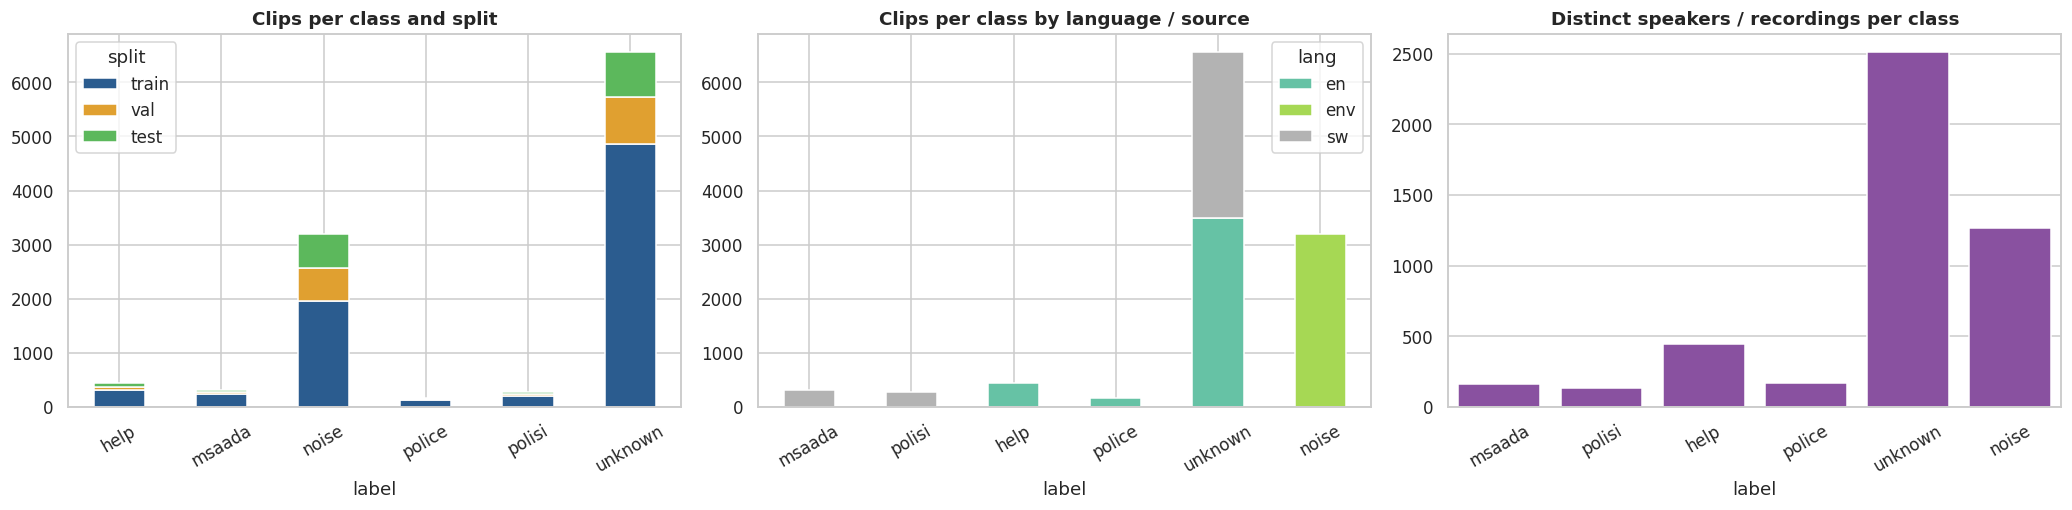

share of each keyword's clips coming from its 5 busiest speakers:
 label
help      0.011
msaada    0.095
police    0.029
polisi    0.112


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
tab.plot(kind="bar", stacked=True, ax=ax[0], color=["#2b5c8f", "#e0a030", "#5cb85c"]); ax[0].set_title("Clips per class and split"); ax[0].tick_params(axis="x", rotation=30)
lang_tab = pd.crosstab(M.label, M.lang).reindex(LABELS)
lang_tab.plot(kind="bar", stacked=True, ax=ax[1], colormap="Set2"); ax[1].set_title("Clips per class by language / source"); ax[1].tick_params(axis="x", rotation=30)
spk_per = M.groupby("label").speaker.nunique().reindex(LABELS)
sns.barplot(x=spk_per.index, y=spk_per.values, ax=ax[2], color="#8e44ad"); ax[2].set_title("Distinct speakers / recordings per class"); ax[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(RES / "eda_class_balance.png", dpi=150); plt.show()

# speaker dominance: the share of a class contributed by its busiest speakers
dom = (M[M.label.isin(TARGETS)].groupby(["label", "speaker"]).size().groupby("label")
       .apply(lambda s: s.sort_values(ascending=False).head(5).sum() / s.sum()))
print("share of each keyword's clips coming from its 5 busiest speakers:\n", dom.round(3).to_string())

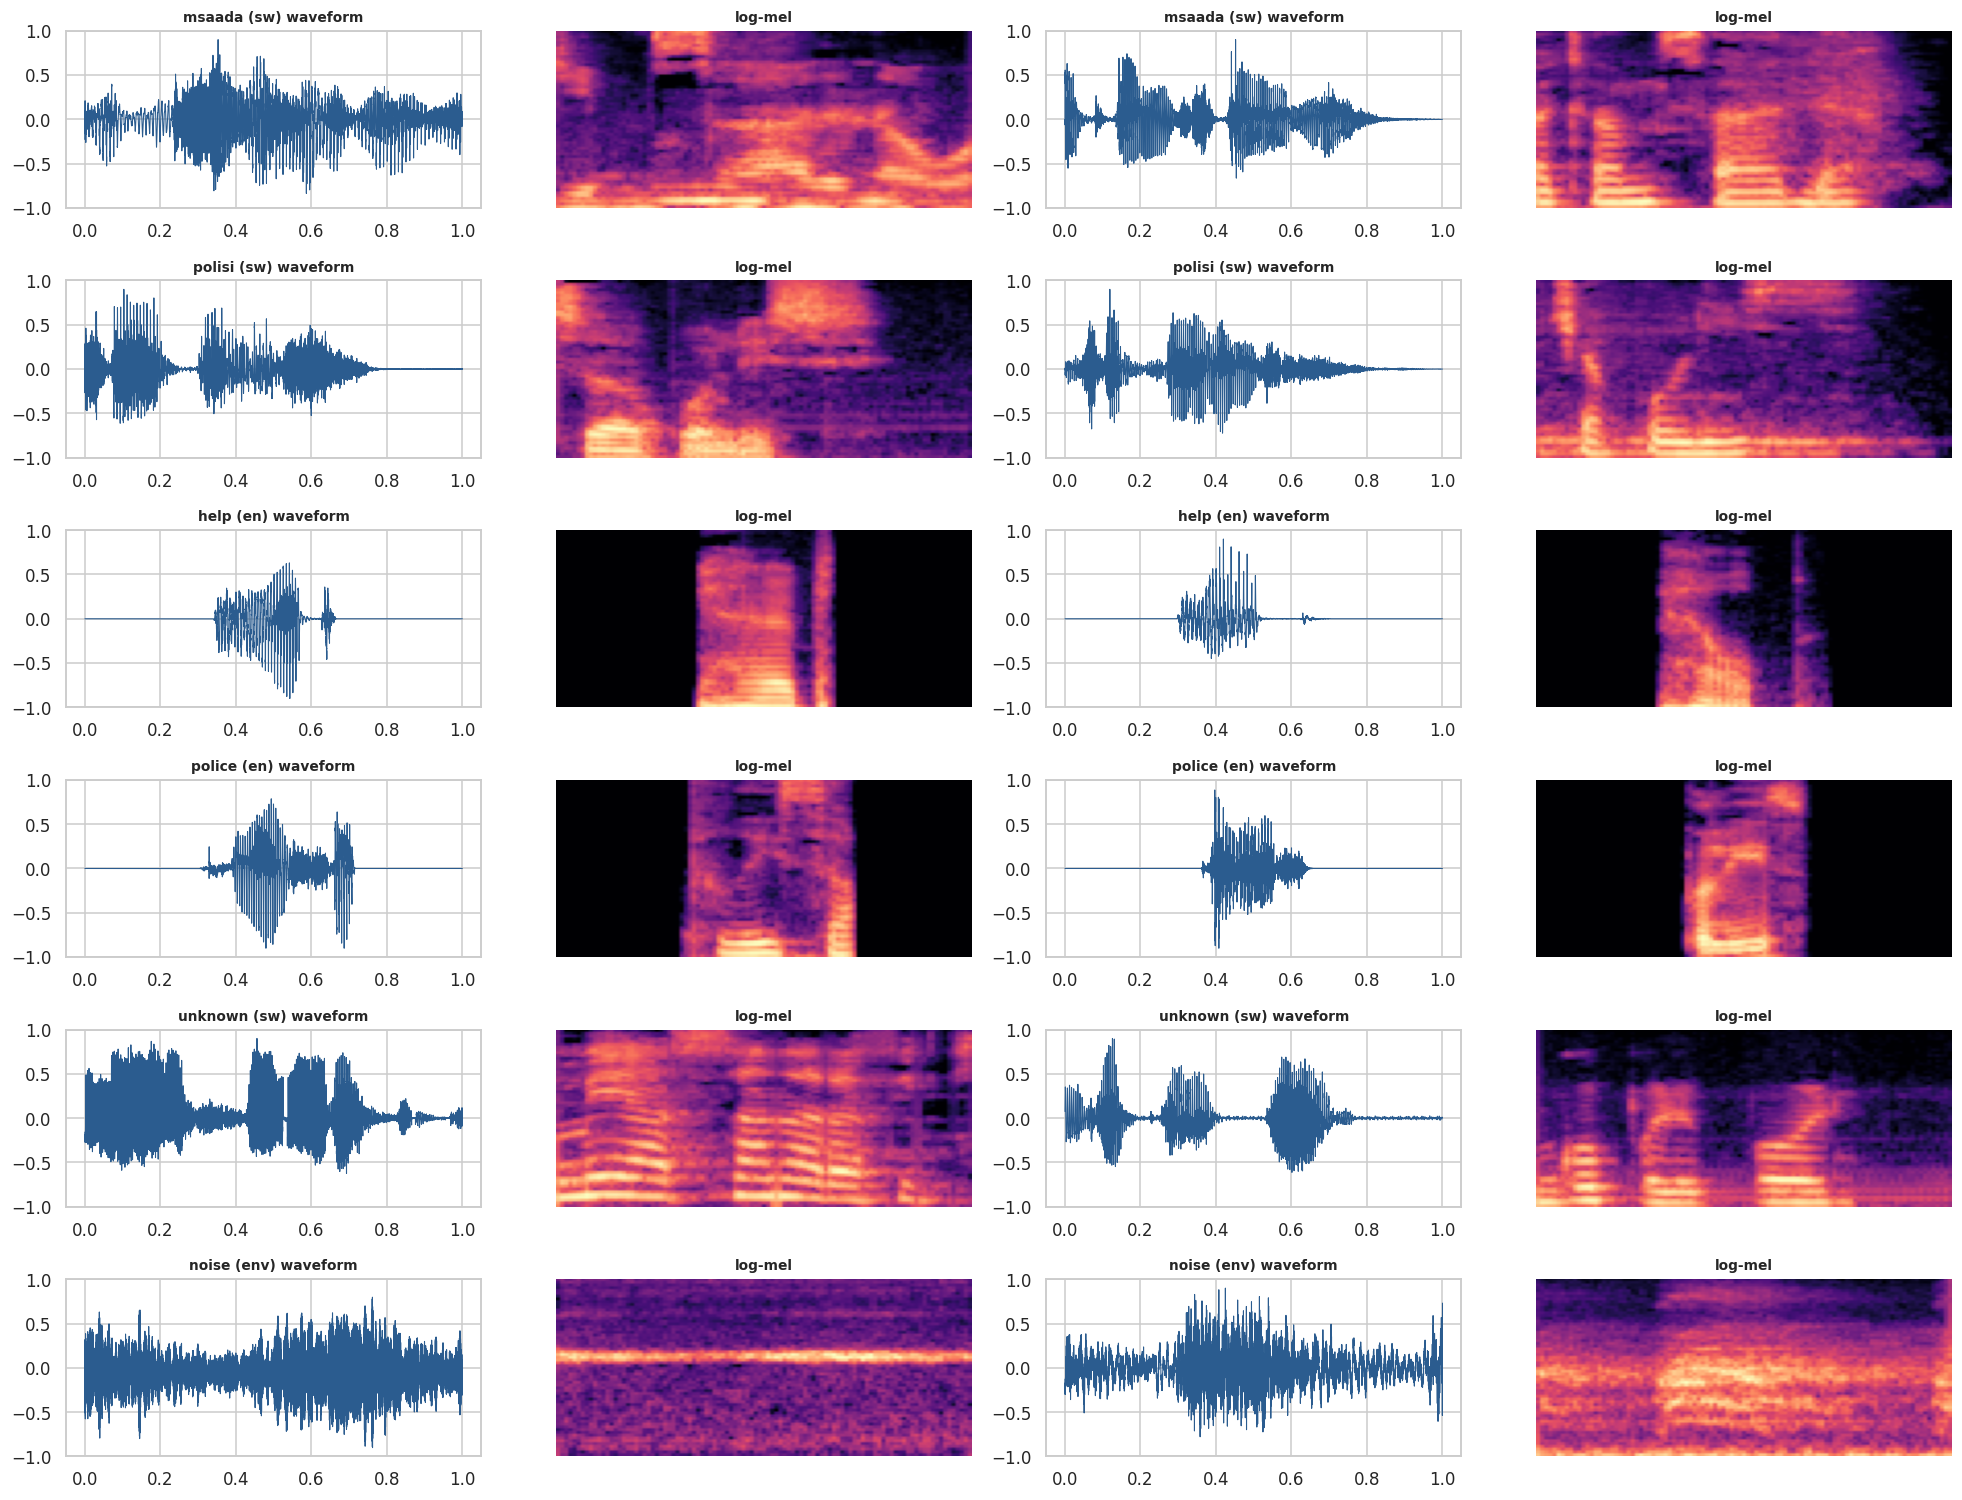

In [ ]:
def logmel_np(x, n_mels=64):
    S = librosa.feature.melspectrogram(y=x, sr=SR, n_fft=512, hop_length=160, n_mels=n_mels, fmin=80, fmax=7600)
    return librosa.power_to_db(S, ref=1.0, top_db=80)

fig, axes = plt.subplots(len(LABELS), 4, figsize=(18, 2.3 * len(LABELS)))
rng = np.random.RandomState(1)
for r, lab in enumerate(LABELS):
    idx = np.where(D["train"]["y"] == LABEL2ID[lab])[0]
    for c, i in enumerate(rng.choice(idx, 2, replace=False)):
        x = D["train"]["X"][i].astype(np.float32) / 32768
        axes[r, 2 * c].plot(np.arange(WIN) / SR, x, lw=0.7, color="#2b5c8f"); axes[r, 2 * c].set_ylim(-1, 1)
        axes[r, 2 * c].set_title(f"{lab} ({D['train']['meta'].lang[i]}) waveform", fontsize=9)
        axes[r, 2 * c + 1].imshow(logmel_np(x), origin="lower", aspect="auto", cmap="magma"); axes[r, 2 * c + 1].set_title("log-mel", fontsize=9)
        axes[r, 2 * c + 1].axis("off")
plt.tight_layout(); plt.savefig(RES / "eda_examples.png", dpi=130); plt.show()

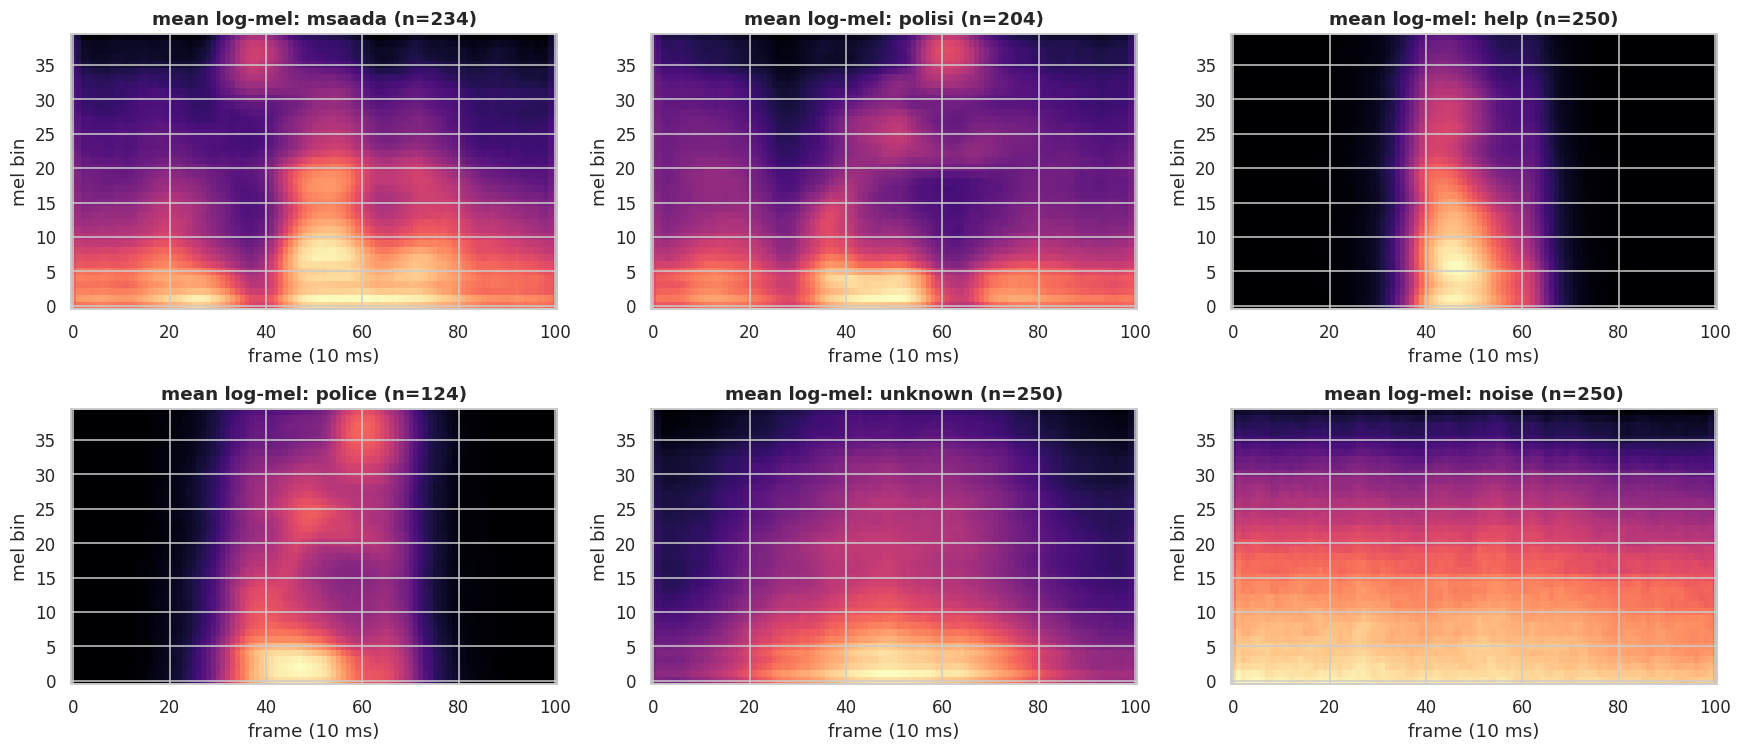

In [ ]:
# Class-average log-mel spectrograms: do the keywords have visibly distinct structure?
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, lab in zip(axes.ravel(), LABELS):
    idx = np.where(D["train"]["y"] == LABEL2ID[lab])[0]
    idx = np.random.RandomState(0).choice(idx, min(250, len(idx)), replace=False)
    avg = np.mean([logmel_np(D["train"]["X"][i].astype(np.float32) / 32768, 40) for i in idx], axis=0)
    ax.imshow(avg, origin="lower", aspect="auto", cmap="magma"); ax.set_title(f"mean log-mel: {lab} (n={len(idx)})")
    ax.set_xlabel("frame (10 ms)"); ax.set_ylabel("mel bin")
plt.tight_layout(); plt.savefig(RES / "eda_mean_spectrograms.png", dpi=130); plt.show()

stats:   0%|          | 0/4000 [00:00<?, ?it/s]

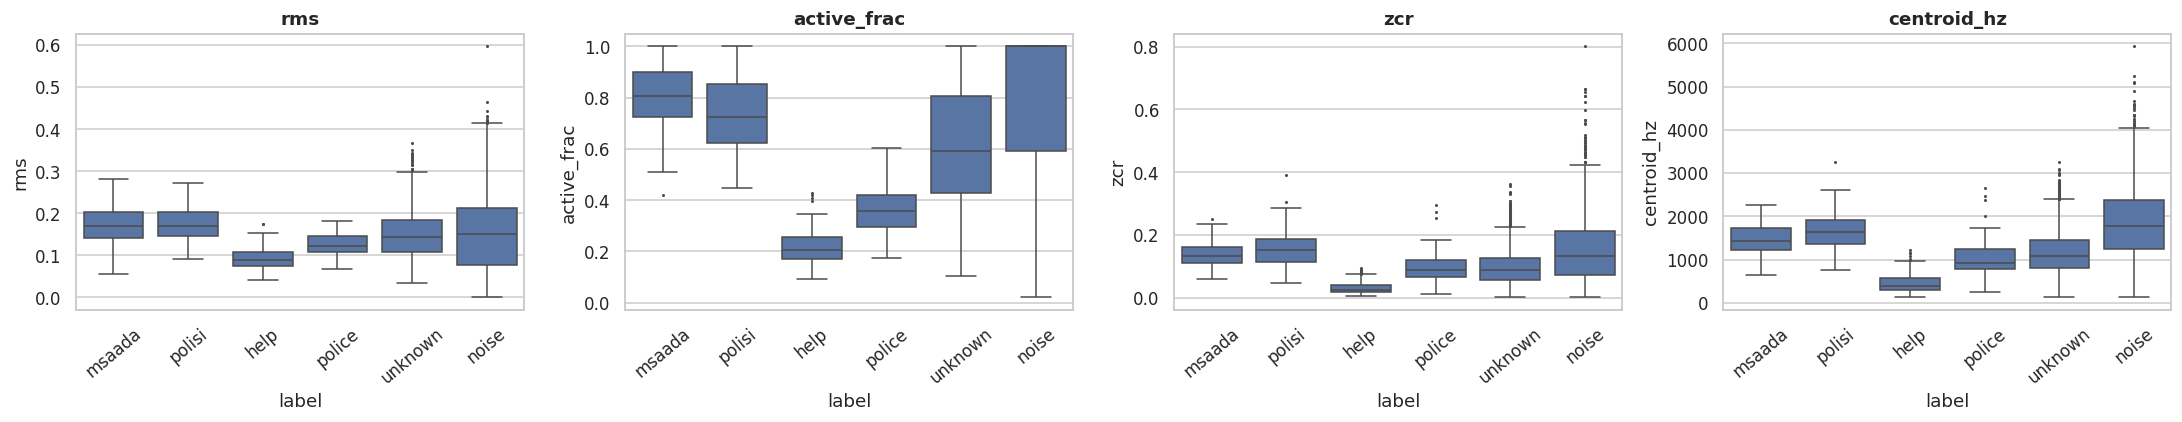

In [ ]:
# Level / activity statistics per class: looks for shortcuts such as "noise is always quieter"
def stats(x):
    x = x.astype(np.float32) / 32768
    rms = np.sqrt(np.mean(x ** 2) + 1e-12)
    frames = librosa.util.frame(x, frame_length=400, hop_length=160)
    e = np.sqrt((frames ** 2).mean(0)); active = (e > 0.1 * e.max()).mean() if e.max() > 0 else 0
    zcr = librosa.feature.zero_crossing_rate(x, frame_length=400, hop_length=160).mean()
    cen = librosa.feature.spectral_centroid(y=x, sr=SR, n_fft=512, hop_length=160).mean()
    return rms, active, zcr, cen

sub = M.sample(min(4000, len(M)), random_state=SEED)
Xs = load_audio(sub.file)
S = pd.DataFrame([stats(x) for x in tqdm(Xs, desc="stats")], columns=["rms", "active_frac", "zcr", "centroid_hz"])
S["label"], S["lang"] = sub.label.values, sub.lang.values
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, c in zip(ax, ["rms", "active_frac", "zcr", "centroid_hz"]):
    sns.boxplot(data=S, x="label", y=c, order=LABELS, ax=a, fliersize=1); a.set_title(c); a.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.savefig(RES / "eda_level_stats.png", dpi=130); plt.show()

In [ ]:
# Shortcut probe: can four crude scalars (level, activity, zero-crossings, centroid) already separate classes?
# High accuracy on keyword-vs-unknown WITHIN a language would mean the data has a non-linguistic shortcut.
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score, GroupKFold
for lang in ["sw", "en"]:
    msk = (S.lang == lang) & S.label.isin(TARGETS + ["unknown"])
    if msk.sum() < 100 or S[msk].label.nunique() < 2: continue
    grp = sub.speaker.values[msk.values]
    acc = cross_val_score(GradientBoostingClassifier(n_estimators=80, random_state=0), S.loc[msk, ["rms", "active_frac", "zcr", "centroid_hz"]],
                          S.loc[msk, "label"], cv=GroupKFold(4), groups=grp).mean()
    chance = S[msk].label.value_counts(normalize=True).max()
    print(f"[{lang}] 4-scalar probe accuracy {acc:.3f} vs majority-class {chance:.3f}  -> "
          f"{'OK (no obvious shortcut)' if acc - chance < 0.12 else 'CAUTION: crude acoustic cues separate the classes'}")

[sw] 4-scalar probe accuracy 0.810 vs majority-class 0.831  -> OK (no obvious shortcut)
[en] 4-scalar probe accuracy 0.883 vs majority-class 0.856  -> OK (no obvious shortcut)


mfcc:   0%|          | 0/2500 [00:00<?, ?it/s]

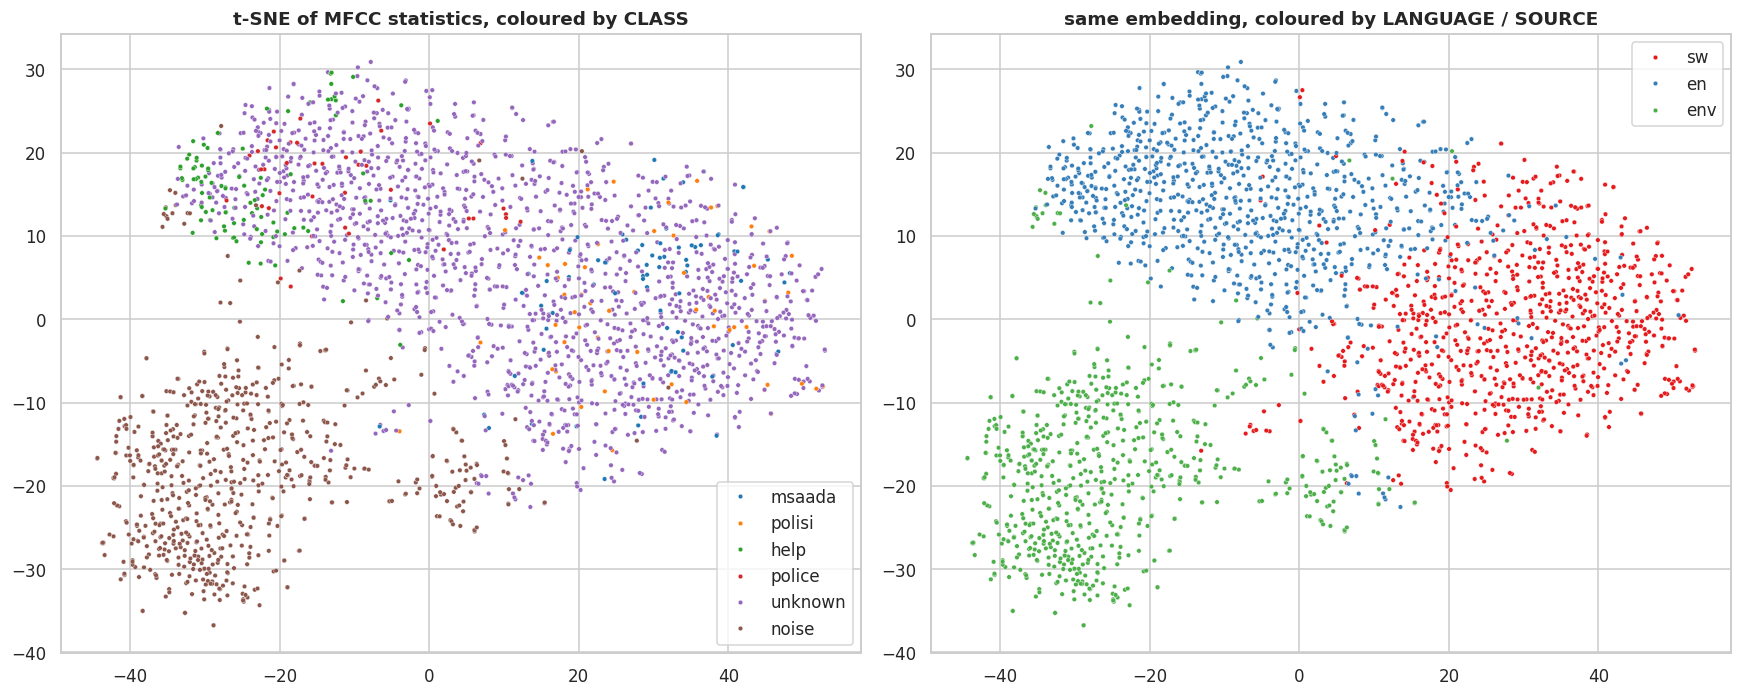

If the right plot separates cleanly by language/source but the left does not separate by word, the model may learn the corpus instead of the word. Balanced `unknown` data in both languages is the countermeasure.


In [ ]:
# 2-D embedding of simple MFCC statistics. Do classes cluster by WORD, or by language/corpus?
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
def mfcc_stats(x):
    x = x.astype(np.float32) / 32768
    m = librosa.feature.mfcc(y=x, sr=SR, n_mfcc=20, n_fft=512, hop_length=160, n_mels=40)
    d = librosa.feature.delta(m)
    return np.concatenate([m.mean(1), m.std(1), d.std(1)])

sub2 = sub.sample(min(2500, len(sub)), random_state=0); X2 = load_audio(sub2.file)
F = np.array([mfcc_stats(x) for x in tqdm(X2, desc="mfcc")])
Z = TSNE(n_components=2, perplexity=35, init="pca", random_state=0).fit_transform((F - F.mean(0)) / (F.std(0) + 1e-8))
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=sub2.label.values, hue_order=LABELS, s=9, ax=ax[0], palette="tab10"); ax[0].set_title("t-SNE of MFCC statistics, coloured by CLASS")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=sub2.lang.values, s=9, ax=ax[1], palette="Set1"); ax[1].set_title("same embedding, coloured by LANGUAGE / SOURCE")
plt.tight_layout(); plt.savefig(RES / "eda_tsne.png", dpi=130); plt.show()
print("If the right plot separates cleanly by language/source but the left does not separate by word, "
      "the model may learn the corpus instead of the word. Balanced `unknown` data in both languages is the countermeasure.")

In [ ]:
# Leakage audit (already asserted above; printed here for the report)
print("Speakers per split:", {k: len(v) for k, v in spk_sets.items()})
print("Overlap train∩val:", len(spk_sets['train'] & spk_sets['val']), "| train∩test:", len(spk_sets['train'] & spk_sets['test']),
      "| val∩test:", len(spk_sets['val'] & spk_sets['test']))
print("Exact-duplicate audio removed:", len(bad))
print("\nPer-split class share (%):")
display((pd.crosstab(M.label, M.split, normalize="columns")[["train", "val", "test"]] * 100).round(1))

Speakers per split: {'train': 2870, 'val': 695, 'test': 696}
Overlap train∩val: 0 | train∩test: 0 | val∩test: 0
Exact-duplicate audio removed: 0

Per-split class share (%):


split,train,val,test
label,,,
help,4.0,4.1,4.1
msaada,3.0,2.8,2.3
noise,25.4,37.2,38.7
police,1.6,1.3,1.6
polisi,2.7,2.0,1.9
unknown,63.3,52.5,51.3


## 4. Preprocessing and augmentation

**Features:** 40-band log-mel spectrogram, 30 ms window / 20 ms hop → 49 × 40 per 1-second clip (cheap enough for an ESP32-C3), standardised with the *training-set* mean/std (these two numbers are exported to firmware).

**Training-time augmentation** (never applied to val/test):
- random time shift ±100 ms (the word will not be centred on a real device)
- random gain 0.4×-1.6×
- **background-noise mixing** at random SNR 0-20 dB using noise clips **from the training noise split only**
- **SpecAugment** (random time and frequency masks)

Class imbalance is handled with class weights.

In [ ]:
N_MELS, FRAME, HOP, NFFT = 40, 480, 320, 512   # 30 ms window / 20 ms hop -> 49 frames (half the DSP cost of 10 ms hop)
N_FRAMES = (WIN - FRAME) // HOP + 1
FEAT_SHAPE = (N_FRAMES, N_MELS, 1)
MEL_W = tf.signal.linear_to_mel_weight_matrix(N_MELS, NFFT // 2 + 1, SR, 80.0, 7600.0)

def logmel_tf(x):
    """x: [..., 16000] float32 in [-1, 1] -> [..., 98, 40] log-mel (same op chain you would port to C)."""
    S = tf.abs(tf.signal.stft(x, FRAME, HOP, NFFT, window_fn=tf.signal.hann_window))
    return tf.math.log(tf.tensordot(tf.square(S), MEL_W, 1) + 1e-6)

def compute_feats(X, chunk=512):
    return np.concatenate([logmel_tf(tf.cast(X[i:i + chunk], tf.float32) / 32768.0).numpy() for i in range(0, len(X), chunk)])

F_train_raw = compute_feats(D["train"]["X"])
MU, SD = float(F_train_raw.mean()), float(F_train_raw.std() + 1e-8)
print(f"feature shape per clip: {FEAT_SHAPE} | train mean={MU:.3f} std={SD:.3f}")
del F_train_raw; gc.collect()

# class weights (balanced)
cnt = np.bincount(D["train"]["y"], minlength=NUM_CLASSES).astype(np.float32)
CLASS_W = (cnt.sum() / (NUM_CLASSES * np.maximum(cnt, 1))).astype(np.float32)
print("class weights:", dict(zip(LABELS, CLASS_W.round(2))))

# noise bank for mixing (train-split noise only)
nb = D["train"]["X"][D["train"]["y"] == LABEL2ID["noise"]][:1500]
NOISE_BANK = tf.constant(nb.astype(np.float32) / 32768.0) if len(nb) else None
print("noise clips available for mixing:", 0 if NOISE_BANK is None else int(NOISE_BANK.shape[0]))

feature shape per clip: (49, 40, 1) | train mean=-3.960 std=6.057
class weights: {'msaada': np.float32(5.48), 'polisi': np.float32(6.29), 'help': np.float32(4.15), 'police': np.float32(10.34), 'unknown': np.float32(0.26), 'noise': np.float32(0.66)}
noise clips available for mixing: 1500


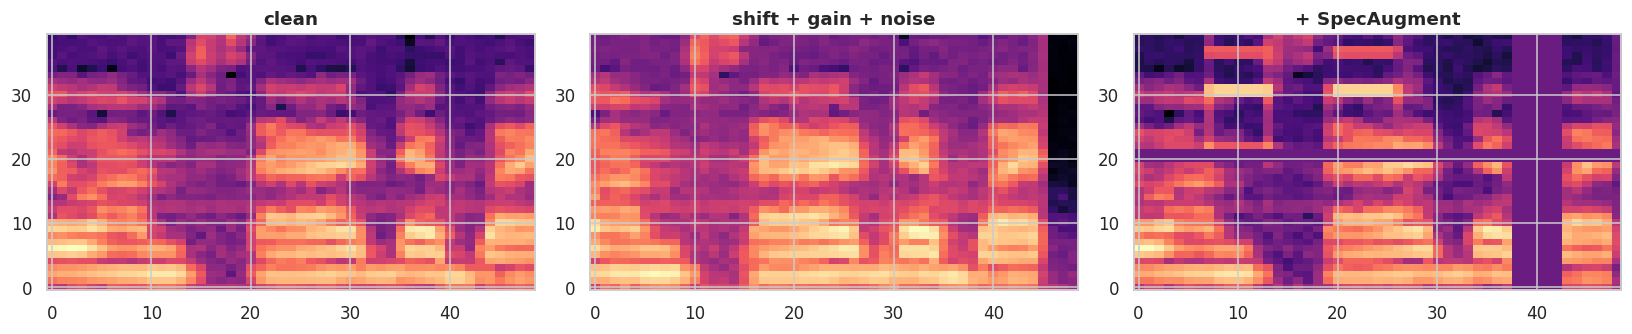

In [ ]:
def augment_wave(x, cfg):
    if cfg.get("shift", True):
        sh = tf.random.uniform([], -1600, 1601, dtype=tf.int32)
        xp = tf.pad(x, [[1600, 1600]])
        x = xp[1600 + sh: 1600 + sh + WIN]
    if cfg.get("gain", True):
        x = tf.clip_by_value(x * tf.exp(tf.random.uniform([], math.log(0.4), math.log(1.6))), -1.0, 1.0)
    p = cfg.get("noise_p", 0.8)
    if p > 0 and NOISE_BANK is not None:
        n = tf.gather(NOISE_BANK, tf.random.uniform([], 0, tf.shape(NOISE_BANK)[0], dtype=tf.int32))
        snr = tf.random.uniform([], cfg.get("snr_lo", 0.0), cfg.get("snr_hi", 20.0))
        rx = tf.sqrt(tf.reduce_mean(tf.square(x)) + 1e-9); rn = tf.sqrt(tf.reduce_mean(tf.square(n)) + 1e-9)
        mixed = x + n * (rx / (rn * tf.pow(10.0, snr / 20.0)))
        x = tf.where(tf.random.uniform([]) < p, mixed, x)
    return tf.clip_by_value(x, -1.0, 1.0)

def spec_augment(f, max_t=6, max_f=6):
    T, F = N_FRAMES, N_MELS
    tw = tf.random.uniform([], 0, max_t + 1, dtype=tf.int32); t0 = tf.random.uniform([], 0, T - max_t, dtype=tf.int32)
    fw = tf.random.uniform([], 0, max_f + 1, dtype=tf.int32); f0 = tf.random.uniform([], 0, F - max_f, dtype=tf.int32)
    tk = tf.logical_or(tf.range(T) < t0, tf.range(T) >= t0 + tw)
    fk = tf.logical_or(tf.range(F) < f0, tf.range(F) >= f0 + fw)
    return f * tf.cast(tf.logical_and(tk[:, None], fk[None, :]), tf.float32)[..., None]

def make_ds(split, cfg=None, training=False, batch=64, idx=None):
    X, y = D[split]["X"], D[split]["y"]
    if idx is not None: X, y = X[idx], y[idx]
    w = CLASS_W[y] if training else np.ones(len(y), np.float32)
    ds = tf.data.Dataset.from_tensor_slices((X, y, w))
    if training: ds = ds.shuffle(len(y), seed=SEED, reshuffle_each_iteration=True)
    def prep(x, yy, ww):
        x = tf.cast(x, tf.float32) / 32768.0
        if training: x = augment_wave(x, cfg)
        f = ((logmel_tf(x) - MU) / SD)[..., None]
        if training and cfg.get("specaug", True): f = spec_augment(f)
        return f, tf.one_hot(yy, NUM_CLASSES), ww
    return ds.map(prep, num_parallel_calls=tf.data.AUTOTUNE).batch(batch).prefetch(tf.data.AUTOTUNE)

# sanity check: show what augmentation does to one clip
cfg_demo = dict(shift=True, gain=True, noise_p=1.0, specaug=True)
i0 = int(np.where(D["train"]["y"] == LABEL2ID[TARGETS[0]])[0][0])
x0 = tf.cast(D["train"]["X"][i0], tf.float32) / 32768.0
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
ax[0].imshow(((logmel_tf(x0) - MU) / SD).numpy().T, origin="lower", aspect="auto", cmap="magma"); ax[0].set_title("clean")
ax[1].imshow(((logmel_tf(augment_wave(x0, cfg_demo)) - MU) / SD).numpy().T, origin="lower", aspect="auto", cmap="magma"); ax[1].set_title("shift + gain + noise")
ax[2].imshow(spec_augment(((logmel_tf(augment_wave(x0, cfg_demo)) - MU) / SD)[..., None]).numpy()[..., 0].T, origin="lower", aspect="auto", cmap="magma"); ax[2].set_title("+ SpecAugment")
plt.tight_layout(); plt.show()

## 5. Baselines
Before any neural network, establish what *simple* models achieve. A DS-CNN is only worth its complexity if it clearly beats these.
1. **Majority class:** the floor.
2. **MFCC statistics + Logistic Regression**
3. **MFCC statistics + Random Forest**

Metrics reported for every model on val and test: **macro-F1** (treats all 6 classes equally), accuracy, **keyword recall** (mean recall over the 4 keywords) and **false-accept rate** (share of `unknown`/`noise` clips wrongly labelled as a keyword). For a safety device the last two matter most.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support

TARGET_IDS = [LABEL2ID[t] for t in TARGETS]
NEG_IDS = [LABEL2ID["unknown"], LABEL2ID["noise"]]

def summarize(y, p):
    kw_mask = np.isin(y, TARGET_IDS); neg_mask = np.isin(y, NEG_IDS)
    return dict(macro_f1=f1_score(y, p, average="macro", labels=range(NUM_CLASSES)), acc=accuracy_score(y, p),
                kw_recall=float((p[kw_mask] == y[kw_mask]).mean()) if kw_mask.any() else np.nan,
                false_accept=float(np.isin(p[neg_mask], TARGET_IDS).mean()) if neg_mask.any() else np.nan)

RESULTS = []
def log_result(name, split, y, p, **extra):
    r = dict(model=name, split=split, **summarize(y, p), **extra); RESULTS.append(r); return r

MF = {s: np.array([mfcc_stats(x) for x in tqdm(D[s]["X"], desc=f"mfcc {s}")]) for s in ["train", "val", "test"]}
baselines = {
    "majority class": DummyClassifier(strategy="most_frequent"),
    "MFCC + LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced", C=0.5)),
    "MFCC + RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
}
for name, clf in baselines.items():
    clf.fit(MF["train"], D["train"]["y"])
    for s in ["val", "test"]:
        log_result(name, s, D[s]["y"], clf.predict(MF[s]))
BASE_DF = pd.DataFrame(RESULTS)
display(BASE_DF.pivot(index="model", columns="split", values=["macro_f1", "kw_recall", "false_accept"]).round(3))

mfcc train:   0%|          | 0/7694 [00:00<?, ?it/s]

mfcc val:   0%|          | 0/1631 [00:00<?, ?it/s]

mfcc test:   0%|          | 0/1647 [00:00<?, ?it/s]

macro_f1        kw_recall        false_accept       
split                   test    val      test    val         test    val
model                                                                   
MFCC + LogReg          0.545  0.526     0.860  0.820        0.256  0.270
MFCC + RandomForest    0.412  0.403     0.189  0.168        0.003  0.004
majority class         0.113  0.115     0.000  0.000        0.000  0.000

## 6. Model: DS-CNN (depthwise-separable CNN)
A compact network built only from operations that TensorFlow Lite Micro supports (Conv2D, DepthwiseConv2D, BatchNorm → folded at conversion, ReLU, global average pooling, Dense/softmax). Width, depth and dropout are hyper-parameters.

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

DEFAULT_CFG = dict(lr=2e-3, width=0.75, blocks=3, dropout=0.2, ls=0.05, batch=64, wd=1e-4,
                   noise_p=0.8, snr_lo=0.0, snr_hi=20.0, shift=True, gain=True, specaug=True)

def build_dscnn(cfg):
    w = cfg["width"]; chans = [max(8, int(round(c * w))) for c in (32, 48, 64, 64)][:cfg["blocks"]]
    c0 = max(8, int(round(16 * w)))
    inp = keras.Input(FEAT_SHAPE)
    x = layers.Conv2D(c0, (5, 3), strides=(2, 2), padding="same", use_bias=False)(inp)
    x = layers.ReLU()(layers.BatchNormalization(momentum=0.9)(x))
    for b, c in enumerate(chans):
        x = layers.DepthwiseConv2D((3, 3), strides=(2, 2) if b == 0 else (1, 1), padding="same", use_bias=False)(x)
        x = layers.ReLU()(layers.BatchNormalization(momentum=0.9)(x))
        x = layers.Conv2D(c, (1, 1), padding="same", use_bias=False)(x)
        x = layers.ReLU()(layers.BatchNormalization(momentum=0.9)(x))
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(cfg["dropout"])(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax", kernel_regularizer=keras.regularizers.l2(1e-4))(x)
    return keras.Model(inp, out, name="safeguard_kws_dscnn")

def predict_probs(model, split, batch=256):
    return model.predict(make_ds(split, None, False, batch), verbose=0)

def train_one(cfg, epochs, verbose=0, train_idx=None):
    keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
    model = build_dscnn(cfg)
    model.compile(keras.optimizers.AdamW(cfg["lr"], weight_decay=cfg.get("wd", 1e-4)),
                  loss=keras.losses.CategoricalCrossentropy(label_smoothing=cfg["ls"]), metrics=["accuracy"])
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=3, factor=0.5, min_lr=1e-5)]
    t0 = time.time()
    h = model.fit(make_ds("train", cfg, True, cfg["batch"], idx=train_idx), validation_data=make_ds("val", None, False, 128),
                  epochs=epochs, callbacks=cb, verbose=verbose)
    P = predict_probs(model, "val"); s = summarize(D["val"]["y"], P.argmax(1))
    return dict(model=model, hist=h.history, params=model.count_params(), secs=time.time() - t0, **{f"val_{k}": v for k, v in s.items()})

def model_cost(model):
    """Parameters, multiply-accumulates per inference, rough INT8 arena and estimated latency (assumption in MCU dict)."""
    macs = 0
    for l in model.layers:
        if not hasattr(l, "output") or l.output is None: continue
        o = l.output.shape
        if isinstance(l, layers.DepthwiseConv2D):
            macs += o[1] * o[2] * l.kernel_size[0] * l.kernel_size[1] * o[3]
        elif isinstance(l, layers.Conv2D):
            macs += o[1] * o[2] * l.kernel_size[0] * l.kernel_size[1] * l.input.shape[-1] * o[3]
        elif isinstance(l, layers.Dense):
            macs += l.input.shape[-1] * o[-1]
    sizes = [int(np.prod(l.output.shape[1:])) for l in model.layers if hasattr(l, "output") and l.output is not None]
    arena = max(a + b for a, b in zip(sizes[:-1], sizes[1:])) / 1024
    return dict(params=int(model.count_params()), macs=int(macs), arena_kb=float(arena), est_ms=macs / MCU["macs_per_sec"] * 1000)

def within_budget(c):
    return (c["params"] <= MCU["params_max"] and c["macs"] <= MCU["macs_max"] and
            c["arena_kb"] <= MCU["arena_kb"] and c["est_ms"] <= MCU["latency_ms_max"])

c0 = model_cost(build_dscnn(DEFAULT_CFG))
print("default model cost:", {k: (round(v, 1) if isinstance(v, float) else v) for k, v in c0.items()}, "| within ESP32-C3 budget:", within_budget(c0))
build_dscnn(DEFAULT_CFG).summary(print_fn=lambda s: print(s) if "Total params" in s or "Param #" in s or "Model:" in s else None)

default model cost: {'params': 4770, 'macs': 548928, 'arena_kb': 12.2, 'est_ms': 54.9} | within ESP32-C3 budget: True


Model: "safeguard_kws_dscnn"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 49, 40, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 25, 20, 12)     │           180 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 25, 20, 12)     │            48 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 25, 20, 12)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_3              │ (None, 13, 

## 7. Hyper-parameter search and ablations

**Random search** over learning rate, width (model size), depth, dropout, label smoothing, batch size, noise-mixing probability and weight decay. Selection uses **validation macro-F1 only**; the test set is not touched until section 9. Each trial is a short training run; the winner is retrained for longer in section 8.

Model size matters as much as accuracy on an ESP32-C3, so results are shown against parameter count (≈ INT8 size in bytes).

In [ ]:
EPOCHS_SEARCH, N_TRIALS, EPOCHS_FINAL, EPOCHS_ABL = (4, 2, 16, 3) if SMOKE_TEST else (14, 12, 45, 14)

def sample_cfg(r):
    """Draw random configs until one fits the ESP32-C3 budget (over-budget models are never trained)."""
    for _ in range(300):
        cfg = dict(DEFAULT_CFG, lr=float(10 ** r.uniform(-3.3, -2.2)), width=float(r.choice([0.5, 0.75, 1.0, 1.5])), blocks=int(r.choice([2, 3, 4])),
                   dropout=float(r.choice([0.1, 0.2, 0.3])), ls=float(r.choice([0.0, 0.05, 0.1])), batch=int(r.choice([32, 64])),
                   noise_p=float(r.choice([0.5, 0.8])), wd=float(r.choice([1e-4, 1e-3])))
        keras.backend.clear_session()
        c = model_cost(build_dscnn(cfg))
        if within_budget(c): return cfg, c
    raise RuntimeError("No configuration fits the MCU budget; relax the MCU dict in the config cell.")

rs = np.random.RandomState(SEED); trials = []
for t in range(N_TRIALS):
    cfg, cost = sample_cfg(rs)
    out = train_one(cfg, EPOCHS_SEARCH)
    row = {k: cfg[k] for k in ["lr", "width", "blocks", "dropout", "ls", "batch", "noise_p", "wd"]}
    row.update(val_macro_f1=out["val_macro_f1"], val_kw_recall=out["val_kw_recall"], val_false_accept=out["val_false_accept"],
               params=out["params"], macs_M=round(cost["macs"] / 1e6, 2), arena_kb=round(cost["arena_kb"], 1), est_ms=round(cost["est_ms"], 1), epochs_run=len(out["hist"]["loss"]), secs=round(out["secs"], 1))
    trials.append(row)
    print(f"trial {t + 1}/{N_TRIALS}: F1={row['val_macro_f1']:.3f} params={row['params']:,} cfg={ {k: row[k] for k in ['lr','width','blocks','dropout']} }")
    del out; gc.collect()
HPO = pd.DataFrame(trials).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
HPO.to_csv(RES / "hpo_trials.csv", index=False)
display(HPO.round(4))
BEST_CFG = dict(DEFAULT_CFG, **{k: float(HPO.loc[0, k]) for k in ["lr", "width", "blocks", "dropout", "ls", "batch", "noise_p", "wd"]})
BEST_CFG["blocks"] = int(BEST_CFG["blocks"]); BEST_CFG["batch"] = int(BEST_CFG["batch"])
print("\nBEST CONFIG:", {k: BEST_CFG[k] for k in ["lr", "width", "blocks", "dropout", "ls", "batch", "noise_p", "wd"]})

trial 1/12: F1=0.473 params=4,110 cfg={'lr': 0.0012941783511729984, 'width': 0.5, 'blocks': 4, 'dropout': 0.3}
trial 2/12: F1=0.473 params=4,770 cfg={'lr': 0.0031203165134715857, 'width': 0.75, 'blocks': 3, 'dropout': 0.2}


trial 3/12: F1=0.467 params=6,918 cfg={'lr': 0.0018933551042526657, 'width': 1.5, 'blocks': 2, 'dropout': 0.1}


trial 4/12: F1=0.403 params=6,918 cfg={'lr': 0.0013204081321129225, 'width': 1.5, 'blocks': 2, 'dropout': 0.3}
trial 5/12: F1=0.343 params=2,310 cfg={'lr': 0.001568733522552853, 'width': 0.75, 'blocks': 2, 'dropout': 0.2}
trial 6/12: F1=0.465 params=4,110 cfg={'lr': 0.002110913126906055, 'width': 0.5, 'blocks': 4, 'dropout': 0.2}
trial 7/12: F1=0.533 params=7,890 cfg={'lr': 0.004834038283055027, 'width': 0.75, 'blocks': 4, 'dropout': 0.3}
trial 8/12: F1=0.342 params=1,286 cfg={'lr': 0.0057185935064703744, 'width': 0.5, 'blocks': 2, 'dropout': 0.2}
trial 9/12: F1=0.444 params=6,918 cfg={'lr': 0.005778043910895514, 'width': 1.5, 'blocks': 2, 'dropout': 0.1}
trial 10/12: F1=0.320 params=1,286 cfg={'lr': 0.0005214348423435606, 'width': 0.5, 'blocks': 2, 'dropout': 0.3}
trial 11/12: F1=0.569 params=4,110 cfg={'lr': 0.0031762003176392588, 'width': 0.5, 'blocks': 4, 'dropout': 0.1}
trial 12/12: F1=0.468 params=2,542 cfg={'lr': 0.005086928613707689, 'width': 0.5, 'blocks': 3, 'dropout': 0.1}


,lr,width,blocks,dropout,ls,batch,noise_p,wd,val_macro_f1,val_kw_recall,val_false_accept,params,macs_M,arena_kb,est_ms,epochs_run,secs
0,0.0032,0.50,4,0.1,0.05,32,0.8,0.0001,0.5685,0.9701,0.2684,4110,0.45,8.1,45.3,14,250.2
1,0.0048,0.75,4,0.3,0.05,32,0.8,0.0001,0.5327,0.9820,0.3429,7890,0.90,12.2,90.5,14,272.0
2,0.0013,0.50,4,0.3,0.00,32,0.5,0.0010,0.4731,0.9341,0.3873,4110,0.45,8.1,45.3,14,253.4
3,0.0031,0.75,3,0.2,0.00,32,0.8,0.0010,0.4729,0.9461,0.3907,4770,0.55,12.2,54.9,14,231.8
4,0.0051,0.50,3,0.1,0.10,32,0.8,0.0010,0.4684,0.9281,0.3941,2542,0.28,8.1,28.3,14,217.6
5,0.0019,1.50,2,0.1,0.10,32,0.5,0.0010,0.4670,0.9281,0.3969,6918,0.86,23.4,86.4,14,234.4
6,0.0021,0.50,4,0.2,0.05,64,0.8,0.0010,0.4652,0.9401,0.4044,4110,0.45,8.1,45.3,14,234.8
7,0.0058,1.50,2,0.1,0.00,32,0.5,0.0001,0.4435,0.8862,0.4426,6918,0.86,23.4,86.4,10,176.0
8,0.0013,1.50,2,0.3,0.00,32,0.5,0.0001,0.4033,0.9281,0.5082,6918,0.86,23.4,86.4,14,232.0
9,0.0016,0.75,2,0.2,0.05,64,0.5,0.0010,0.3427,0.6826,0.4734,2310,0.28,11.7,28.2,10,147.6



BEST CONFIG: {'lr': 0.0031762003176392588, 'width': 0.5, 'blocks': 4, 'dropout': 0.1, 'ls': 0.05, 'batch': 32, 'noise_p': 0.8, 'wd': 0.0001}


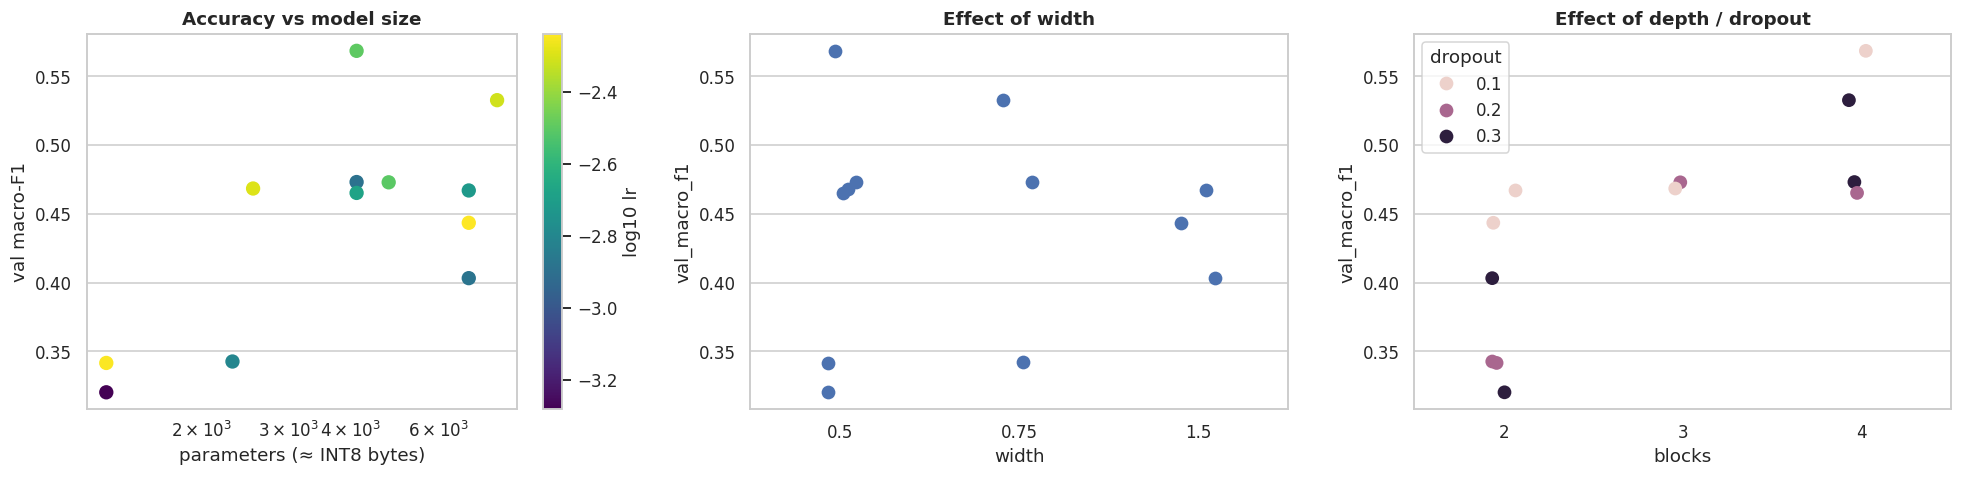

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
sc = ax[0].scatter(HPO.params, HPO.val_macro_f1, c=np.log10(HPO.lr), cmap="viridis", s=70)
ax[0].set_xscale("log"); ax[0].set_xlabel("parameters (≈ INT8 bytes)"); ax[0].set_ylabel("val macro-F1"); ax[0].set_title("Accuracy vs model size"); plt.colorbar(sc, ax=ax[0], label="log10 lr")
sns.stripplot(data=HPO, x="width", y="val_macro_f1", ax=ax[1], size=9); ax[1].set_title("Effect of width")
sns.stripplot(data=HPO, x="blocks", y="val_macro_f1", hue="dropout", ax=ax[2], size=9); ax[2].set_title("Effect of depth / dropout")
plt.tight_layout(); plt.savefig(RES / "hpo_overview.png", dpi=140); plt.show()

full recipe                F1=0.538  kw_recall=0.850  false_accept=0.2917
no noise mixing            F1=0.617  kw_recall=0.946  false_accept=0.2049
no SpecAugment             F1=0.653  kw_recall=0.946  false_accept=0.1803
no time shift              F1=0.601  kw_recall=0.964  false_accept=0.2281
no gain jitter             F1=0.535  kw_recall=0.964  false_accept=0.3149
no augmentation at all     F1=0.698  kw_recall=0.934  false_accept=0.1284


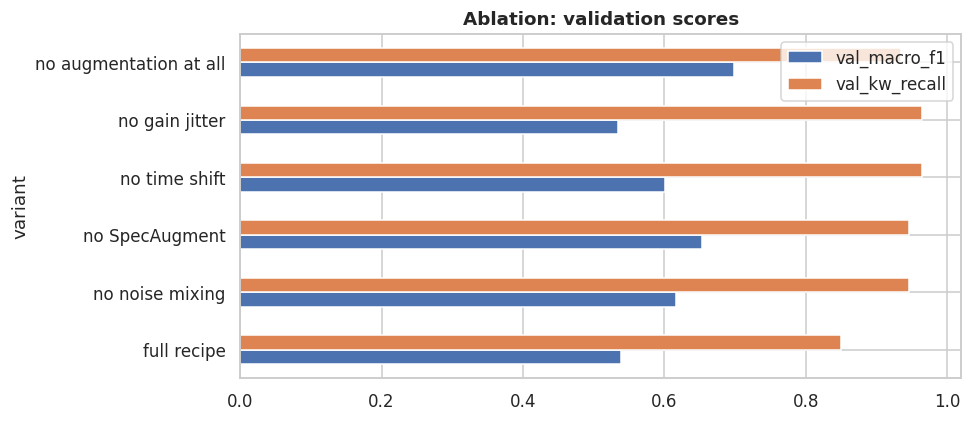

In [ ]:
# ---- Ablations: what does each ingredient actually buy? (best config, validation set) ----
variants = {"full recipe": {}, "no noise mixing": dict(noise_p=0.0), "no SpecAugment": dict(specaug=False),
            "no time shift": dict(shift=False), "no gain jitter": dict(gain=False),
            "no augmentation at all": dict(noise_p=0.0, specaug=False, shift=False, gain=False)}
abl = []
for name, ch in variants.items():
    o = train_one(dict(BEST_CFG, **ch), EPOCHS_ABL)
    abl.append(dict(variant=name, val_macro_f1=o["val_macro_f1"], val_kw_recall=o["val_kw_recall"], val_false_accept=o["val_false_accept"]))
    print(f"{name:26s} F1={o['val_macro_f1']:.3f}  kw_recall={o['val_kw_recall']:.3f}  false_accept={o['val_false_accept']:.4f}")
    del o; gc.collect()
ABL = pd.DataFrame(abl); ABL.to_csv(RES / "ablations.csv", index=False)
ABL.set_index("variant")[["val_macro_f1", "val_kw_recall"]].plot(kind="barh", figsize=(9, 4)); plt.title("Ablation: validation scores"); plt.xlim(0, 1.02); plt.tight_layout(); plt.show()

,train_fraction,n_train,val_macro_f1
0,0.25,1923,0.349
1,0.50,3847,0.449
2,1.00,7694,0.539


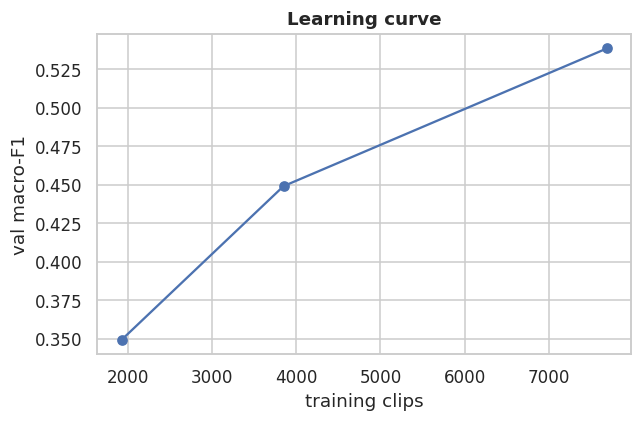

If the curve is still rising at 100 %, collecting more speakers will help. If it has flattened, the limit is data quality/mismatch, not quantity.


In [ ]:
# ---- Learning curve: would more data help? ----
fracs = [0.25, 0.5, 1.0]; lc = []
rng_lc = np.random.RandomState(SEED)
for fr in fracs:
    idx = np.sort(rng_lc.choice(len(D["train"]["y"]), int(fr * len(D["train"]["y"])), replace=False)) if fr < 1 else None
    o = train_one(BEST_CFG, EPOCHS_ABL, train_idx=idx)
    lc.append(dict(train_fraction=fr, n_train=len(idx) if idx is not None else len(D["train"]["y"]), val_macro_f1=o["val_macro_f1"]))
    del o; gc.collect()
LC = pd.DataFrame(lc); display(LC.round(3))
plt.figure(figsize=(6, 4)); plt.plot(LC.n_train, LC.val_macro_f1, "o-"); plt.xlabel("training clips"); plt.ylabel("val macro-F1"); plt.title("Learning curve"); plt.grid(True); plt.tight_layout(); plt.show()
print("If the curve is still rising at 100 %, collecting more speakers will help. If it has flattened, the limit is data quality/mismatch, not quantity.")

## 8. Final training
The winning configuration is trained for longer with early stopping on validation loss. The test set is still untouched.

Epoch 1/45
241/241 - 23s - 94ms/step - accuracy: 0.2294 - loss: 1.6058 - val_accuracy: 0.3709 - val_loss: 1.3849 - learning_rate: 0.0032
Epoch 2/45
241/241 - 14s - 59ms/step - accuracy: 0.3088 - loss: 1.3864 - val_accuracy: 0.4635 - val_loss: 1.2967 - learning_rate: 0.0032
Epoch 3/45
241/241 - 14s - 59ms/step - accuracy: 0.4001 - loss: 1.2014 - val_accuracy: 0.5414 - val_loss: 1.1566 - learning_rate: 0.0032
Epoch 4/45
241/241 - 17s - 73ms/step - accuracy: 0.4359 - loss: 1.1221 - val_accuracy: 0.5469 - val_loss: 1.2178 - learning_rate: 0.0032
Epoch 5/45
241/241 - 15s - 60ms/step - accuracy: 0.4578 - loss: 1.0727 - val_accuracy: 0.5236 - val_loss: 1.2598 - learning_rate: 0.0032
Epoch 6/45
241/241 - 21s - 85ms/step - accuracy: 0.4589 - loss: 1.0328 - val_accuracy: 0.6793 - val_loss: 0.9034 - learning_rate: 0.0032
Epoch 7/45
241/241 - 15s - 60ms/step - accuracy: 0.4866 - loss: 0.9672 - val_accuracy: 0.6278 - val_loss: 0.9942 - learning_rate: 0.0032
Epoch 8/45
241/241 - 14s - 60ms/step - ac

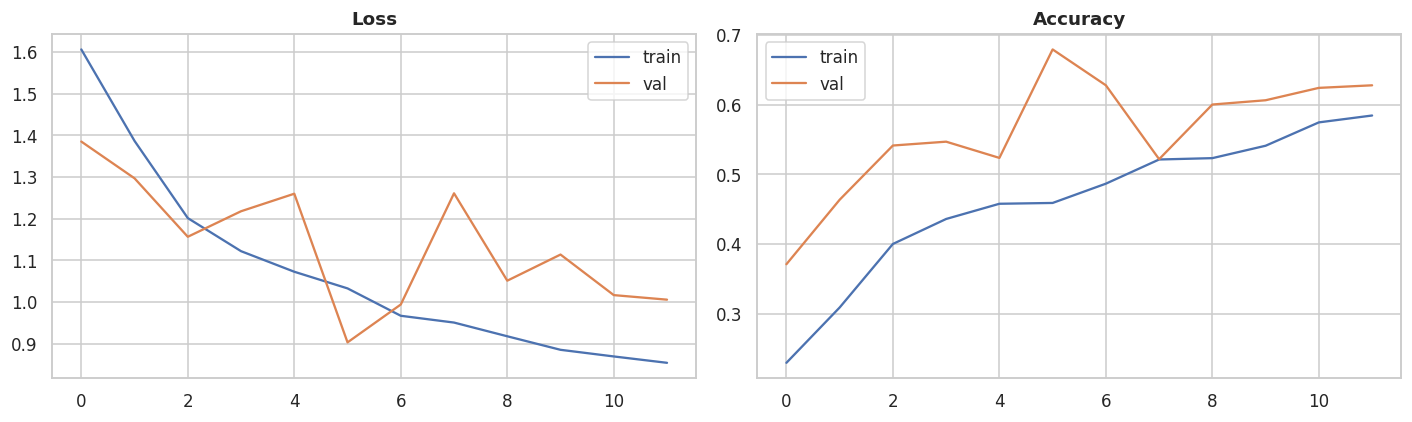

parameters: 4,110 | val macro-F1 0.505 | kw recall 0.904 | false-accept 0.3361


In [ ]:
final = train_one(BEST_CFG, EPOCHS_FINAL, verbose=2)
MODEL = final["model"]; HIST = final["hist"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(HIST["loss"], label="train"); ax[0].plot(HIST["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(HIST["accuracy"], label="train"); ax[1].plot(HIST["val_accuracy"], label="val"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.tight_layout(); plt.savefig(RES / "training_curves.png", dpi=140); plt.show()
MODEL.save(RES / "safeguard_kws_dscnn.keras")
print(f"parameters: {final['params']:,} | val macro-F1 {final['val_macro_f1']:.3f} | kw recall {final['val_kw_recall']:.3f} | false-accept {final['val_false_accept']:.4f}")
for s in ["val", "test"]:
    log_result("DS-CNN (float32)", s, D[s]["y"], predict_probs(MODEL, s).argmax(1), params=final["params"])

## 9. Evaluation (test set, first and only look)
Everything below uses the **speaker-disjoint test split**. Sections: overall metrics vs baselines → per-class and per-language → ROC/PR → robustness to noise and loudness → **streaming simulation of the two-detection trigger rule** (the number that actually describes the product) → error analysis.

              precision    recall  f1-score   support

      msaada      0.167     0.763     0.274        38
      polisi      0.205     0.774     0.324        31
        help      0.330     0.941     0.489        68
      police      0.213     1.000     0.351        27
     unknown      0.937     0.512     0.663       845
       noise      0.998     0.897     0.945       638

    accuracy                          0.698      1647
   macro avg      0.475     0.815     0.507      1647
weighted avg      0.892     0.698     0.744      1647



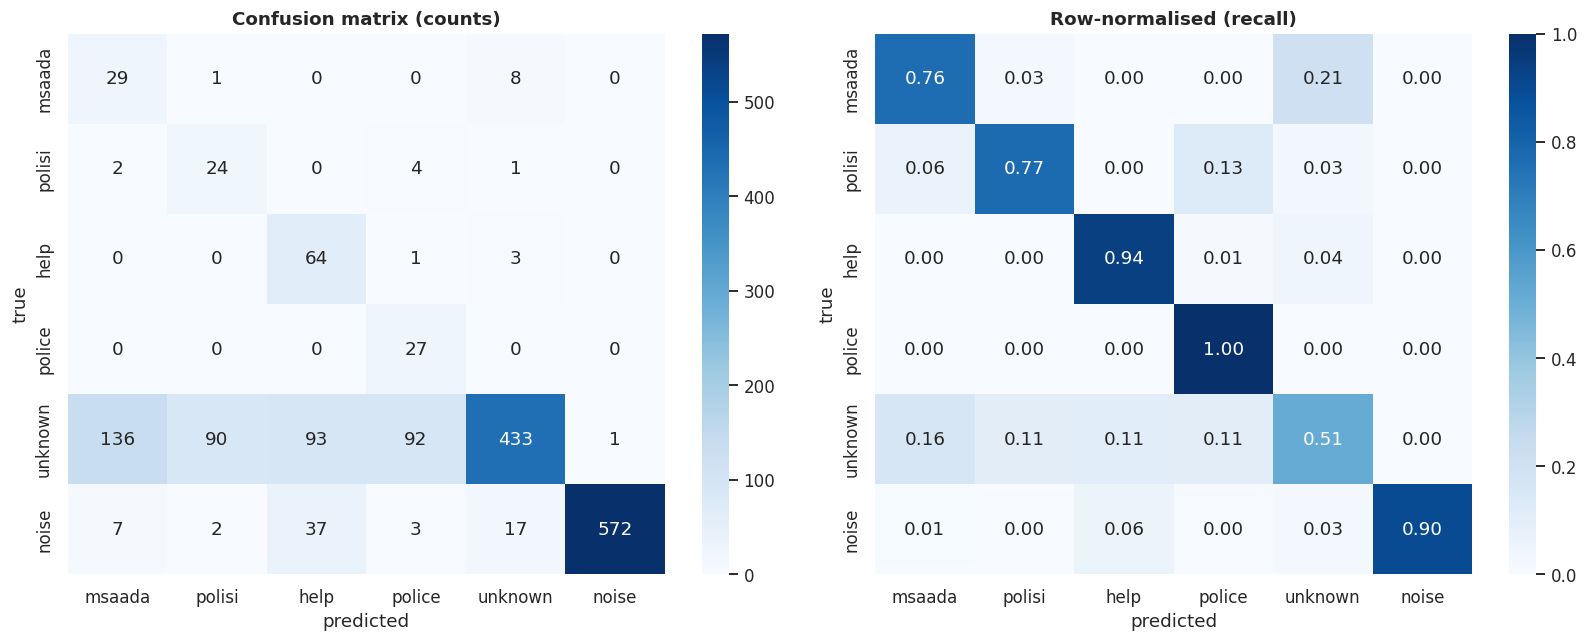

,macro_f1,acc,kw_recall,false_accept
model,,,,
majority class,0.113,0.513,0.000,0.000
MFCC + LogReg,0.545,0.748,0.860,0.256
MFCC + RandomForest,0.412,0.891,0.189,0.003
DS-CNN (float32),0.507,0.698,0.878,0.310


In [ ]:
P_test = predict_probs(MODEL, "test"); y_test = D["test"]["y"]; p_test = P_test.argmax(1)
print(classification_report(y_test, p_test, labels=range(NUM_CLASSES), target_names=LABELS, digits=3, zero_division=0))

cm = confusion_matrix(y_test, p_test, labels=range(NUM_CLASSES)); cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=ax[0]); ax[0].set_title("Confusion matrix (counts)")
sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=ax[1], vmin=0, vmax=1); ax[1].set_title("Row-normalised (recall)")
for a in ax: a.set_xlabel("predicted"); a.set_ylabel("true")
plt.tight_layout(); plt.savefig(RES / "confusion_matrix.png", dpi=150); plt.show()

R = pd.DataFrame(RESULTS); T = R[R.split == "test"].drop(columns=["split"]).set_index("model")
display(T[["macro_f1", "acc", "kw_recall", "false_accept"]].round(3))

In [ ]:
# ---- per-language breakdown ----
meta = D["test"]["meta"].copy(); meta["y"], meta["p"] = y_test, p_test
rows = []
for lab in TARGETS:
    s = meta[meta.label == lab]
    rows.append(dict(group=f"{lab} ({LANG_OF[lab]})", n=len(s), recall=(s.p == s.y).mean(),
                     confused_with_other_language_kw=np.isin(s.p, [LABEL2ID[t] for t in TARGETS if LANG_OF[t] != LANG_OF[lab]]).mean(),
                     predicted_unknown_or_noise=np.isin(s.p, NEG_IDS).mean()))
for lang in ["sw", "en"]:
    s = meta[(meta.label == "unknown") & (meta.lang == lang)]
    if len(s): rows.append(dict(group=f"unknown speech ({lang}) -> false accept", n=len(s), recall=np.nan,
                                confused_with_other_language_kw=np.nan, predicted_unknown_or_noise=np.nan, false_accept=np.isin(s.p, TARGET_IDS).mean()))
s = meta[meta.label == "noise"]
if len(s): rows.append(dict(group="noise -> false accept", n=len(s), false_accept=np.isin(s.p, TARGET_IDS).mean()))
LANG_TAB = pd.DataFrame(rows); display(LANG_TAB.round(3))

real = meta[meta.source == "real"]
if len(real):
    print("\n=== REAL-DEVICE RECORDINGS (the numbers to trust) ===")
    print(classification_report(real.y, real.p, labels=range(NUM_CLASSES), target_names=LABELS, zero_division=0))
else:
    print("\nNo real recordings in `real/` yet. Record some on the pendant mic and re-run from section 2.")

,group,n,recall,confused_with_other_language_kw,predicted_unknown_or_noise,false_accept
0,msaada (sw),38,0.763,0.000,0.211,NaN
1,polisi (sw),31,0.774,0.129,0.032,NaN
2,help (en),68,0.941,0.000,0.044,NaN
3,police (en),27,1.000,0.000,0.000,NaN
4,unknown speech (sw) -> false accept,323,NaN,NaN,NaN,0.619
5,unknown speech (en) -> false accept,522,NaN,NaN,NaN,0.404
6,noise -> false accept,638,NaN,NaN,NaN,0.077



No real recordings in `real/` yet. Record some on the pendant mic and re-run from section 2.


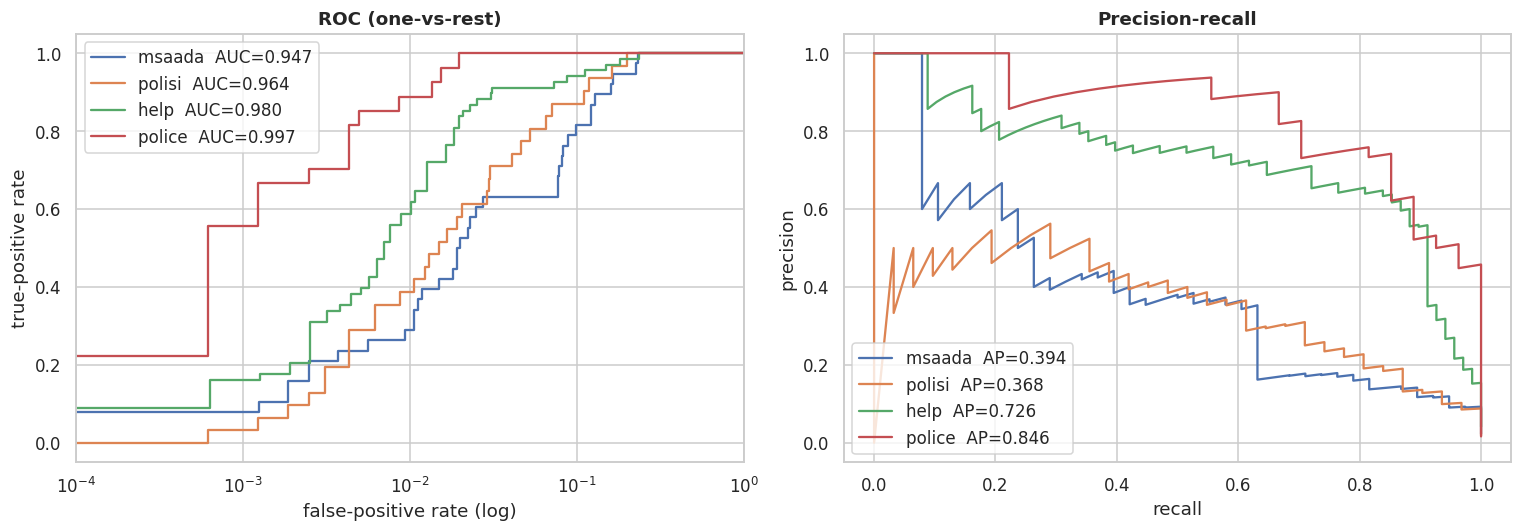

In [ ]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for t in TARGETS:
    i = LABEL2ID[t]; yt = (y_test == i).astype(int)
    if yt.sum() == 0: continue
    fpr, tpr, _ = roc_curve(yt, P_test[:, i]); pr, rc, _ = precision_recall_curve(yt, P_test[:, i])
    ax[0].plot(fpr, tpr, label=f"{t}  AUC={auc(fpr, tpr):.3f}"); ax[1].plot(rc, pr, label=f"{t}  AP={average_precision_score(yt, P_test[:, i]):.3f}")
ax[0].set_xscale("log"); ax[0].set_xlim(1e-4, 1); ax[0].set_xlabel("false-positive rate (log)"); ax[0].set_ylabel("true-positive rate"); ax[0].set_title("ROC (one-vs-rest)"); ax[0].legend()
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("Precision-recall"); ax[1].legend()
plt.tight_layout(); plt.savefig(RES / "roc_pr.png", dpi=150); plt.show()

,condition,macro_f1,acc,kw_recall,false_accept
0,clean,0.506,0.697,0.872,0.310
1,+noise 20 dB SNR,0.503,0.678,0.896,0.336
2,+noise 10 dB SNR,0.491,0.667,0.848,0.330
3,+noise 5 dB SNR,0.443,0.615,0.738,0.349
4,+noise 0 dB SNR,0.395,0.554,0.622,0.332
5,gain x0.1,0.267,0.474,0.451,0.358
6,gain x0.25,0.452,0.635,0.799,0.353
7,gain x2.0,0.531,0.723,0.848,0.277


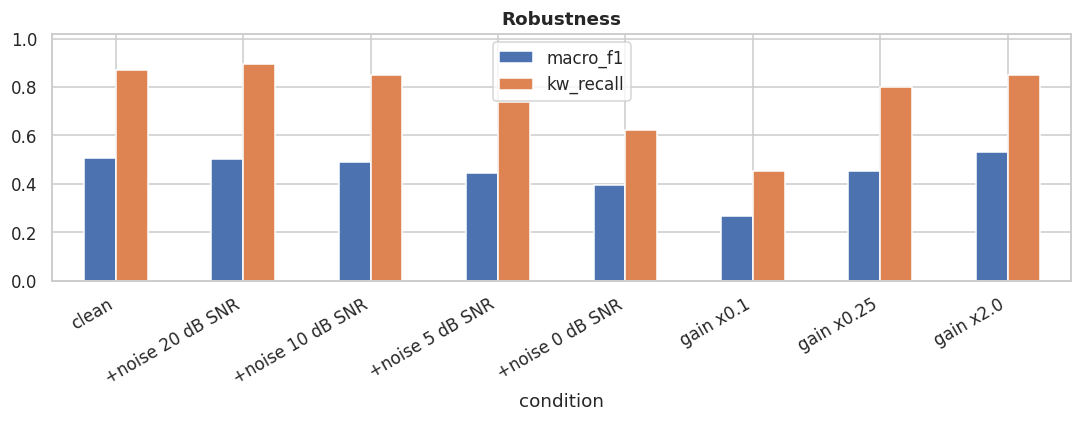

In [ ]:
# ---- robustness: additive noise at fixed SNR, and loudness changes (noise taken from TEST noise clips only) ----
nz_test = D["test"]["X"][y_test == LABEL2ID["noise"]].astype(np.float32) / 32768.0
def eval_variant(X_f32):
    Xi = np.clip(X_f32 * 32767, -32768, 32767).astype(np.int16)
    F = (compute_feats(Xi) - MU) / SD
    p = MODEL.predict(F[..., None], batch_size=256, verbose=0).argmax(1)
    return summarize(y_test, p)

rng = np.random.RandomState(0); Xt = D["test"]["X"].astype(np.float32) / 32768.0
snr_rows = [dict(condition="clean", **eval_variant(Xt))]
if len(nz_test):
    for snr in [20, 10, 5, 0]:
        N = nz_test[rng.randint(0, len(nz_test), len(Xt))]
        rx = np.sqrt((Xt ** 2).mean(1, keepdims=True) + 1e-9); rn = np.sqrt((N ** 2).mean(1, keepdims=True) + 1e-9)
        snr_rows.append(dict(condition=f"+noise {snr} dB SNR", **eval_variant(np.clip(Xt + N * rx / (rn * 10 ** (snr / 20)), -1, 1))))
for g in [0.1, 0.25, 2.0]:
    snr_rows.append(dict(condition=f"gain x{g}", **eval_variant(np.clip(Xt * g, -1, 1))))
ROB = pd.DataFrame(snr_rows); display(ROB.round(3))
ROB.set_index("condition")[["macro_f1", "kw_recall"]].plot(kind="bar", figsize=(10, 4)); plt.ylim(0, 1.02); plt.title("Robustness"); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

### 9b. Streaming simulation: what the *device* would actually do
Per-clip accuracy is not the product. The product is: *"how often does it raise a false alert, and how often does it fire when someone really calls for help?"*

The simulation slides the model over continuous audio every 0.25 s (as the firmware would), turns above-threshold scores into **events**, and applies the trigger rule: **alert only if two events occur within 4 s** (cool-down 10 s afterwards).

- **Negative stream:** all test `unknown` + `noise` clips concatenated. This is *harsher than real life*, because it is continuous speech/noise with no quiet gaps, and has no keywords.
- **Positive trials:** 10-second noisy backgrounds with **two** keyword utterances (1-3 s apart, 5-20 dB SNR) → should alert.
- **Single-word trials:** only **one** keyword → the pair rule should *not* alert (this is the safety property).

In [ ]:
def stream_probs(wave):
    W = np.lib.stride_tricks.sliding_window_view(wave.astype(np.float32), WIN)[::int(HOP_S * SR)]
    out = []
    for i in range(0, len(W), 512):
        f = (logmel_tf(tf.constant(W[i:i + 512])).numpy() - MU) / SD
        out.append(MODEL.predict(f[..., None], batch_size=256, verbose=0))
    return np.concatenate(out)

def events_from(P, thr):
    score = P[:, TARGET_IDS].max(1); ev, last = [], -1e9
    for k in np.where(score >= thr)[0]:
        t = k * HOP_S
        if t - last >= REFRACTORY_S: ev.append(t)
        last = t
    return ev

def alerts_from(P, thr, mode):
    ev = events_from(P, thr); out, cool = [], -1e9
    if mode == "single":
        for t in ev:
            if t - cool >= COOLDOWN_S: out.append(t); cool = t
    else:
        for j in range(1, len(ev)):
            if ev[j] - cool >= COOLDOWN_S and ev[j] - ev[j - 1] <= PAIR_WINDOW_S: out.append(ev[j]); cool = ev[j]
    return out

# ---- negative stream ----
neg_idx = np.where(np.isin(y_test, NEG_IDS))[0]; rng = np.random.RandomState(7); rng.shuffle(neg_idx)
neg_wave = np.concatenate([Xt[i] for i in neg_idx]); neg_hours = len(neg_wave) / SR / 3600
P_neg = stream_probs(neg_wave)
print(f"negative stream: {len(neg_wave) / SR / 60:.1f} min ({len(neg_idx)} clips)")

# ---- positive / single-word trials ----
pos_pool = {t: np.where(y_test == LABEL2ID[t])[0] for t in TARGETS if (y_test == LABEL2ID[t]).any()}
def make_trial(n_words, rng, dur=10.0):
    if len(nz_test):
        bg = np.concatenate([nz_test[rng.randint(len(nz_test))] for _ in range(int(dur))])[:int(dur * SR)].copy()
    else:
        bg = rng.randn(int(dur * SR)).astype(np.float32) * 0.01
    t = rng.uniform(1.0, 2.5)
    for w in range(n_words):
        lab = list(pos_pool)[rng.randint(len(pos_pool))]; clip = Xt[rng.choice(pos_pool[lab])]
        snr = rng.uniform(5, 20); rb = np.sqrt((bg ** 2).mean() + 1e-9); rc = np.sqrt((clip ** 2).mean() + 1e-9)
        a = int(t * SR); bg[a:a + WIN] += clip * rb / (rc * 10 ** (snr / 20)) if rb > 1e-4 else clip * 0.3
        t += rng.uniform(1.0, 3.0)
    return np.clip(bg, -1, 1)

N_TRIALS_STREAM = 40 if SMOKE_TEST else 300
rt = np.random.RandomState(11)
P_pair = [stream_probs(make_trial(2, rt)) for _ in tqdm(range(N_TRIALS_STREAM), desc="two-word trials")]
P_one  = [stream_probs(make_trial(1, rt)) for _ in tqdm(range(N_TRIALS_STREAM), desc="one-word trials")]

thr_grid = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99]
sim = []
for thr in thr_grid:
    fa_single = len(alerts_from(P_neg, thr, "single")) / neg_hours
    fa_pair = len(alerts_from(P_neg, thr, "pair")) / neg_hours
    sim.append(dict(threshold=thr, false_alerts_per_hr_single_rule=fa_single, false_alerts_per_hr_pair_rule=fa_pair,
                    trigger_rate_two_words=np.mean([len(alerts_from(P, thr, "pair")) > 0 for P in P_pair]),
                    alert_rate_one_word_pair_rule=np.mean([len(alerts_from(P, thr, "pair")) > 0 for P in P_one]),
                    alert_rate_one_word_single_rule=np.mean([len(alerts_from(P, thr, "single")) > 0 for P in P_one])))
SIM = pd.DataFrame(sim); display(SIM.round(3))
print(f"(Negative stream length {neg_hours * 60:.1f} min. With zero alerts the 95 % upper bound is ≈ {3 / neg_hours:.1f} false alerts/hour; "
      "a long, real-life recording is needed to claim anything per-day.)")

negative stream: 24.7 min (1483 clips)


two-word trials:   0%|          | 0/300 [00:00<?, ?it/s]

one-word trials:   0%|          | 0/300 [00:00<?, ?it/s]

,threshold,false_alerts_per_hr_single_rule,false_alerts_per_hr_pair_rule,trigger_rate_two_words,alert_rate_one_word_pair_rule,alert_rate_one_word_single_rule
0,0.50,288.874,233.041,0.290,0.187,0.660
1,0.60,240.324,145.651,0.117,0.083,0.450
2,0.70,182.063,60.688,0.023,0.033,0.283
3,0.80,106.811,16.993,0.007,0.010,0.147
4,0.90,26.703,0.000,0.000,0.000,0.023
5,0.95,7.283,0.000,0.000,0.000,0.003
6,0.98,0.000,0.000,0.000,0.000,0.000
7,0.99,0.000,0.000,0.000,0.000,0.000


(Negative stream length 24.7 min. With zero alerts the 95 % upper bound is ≈ 7.3 false alerts/hour; a long, real-life recording is needed to claim anything per-day.)


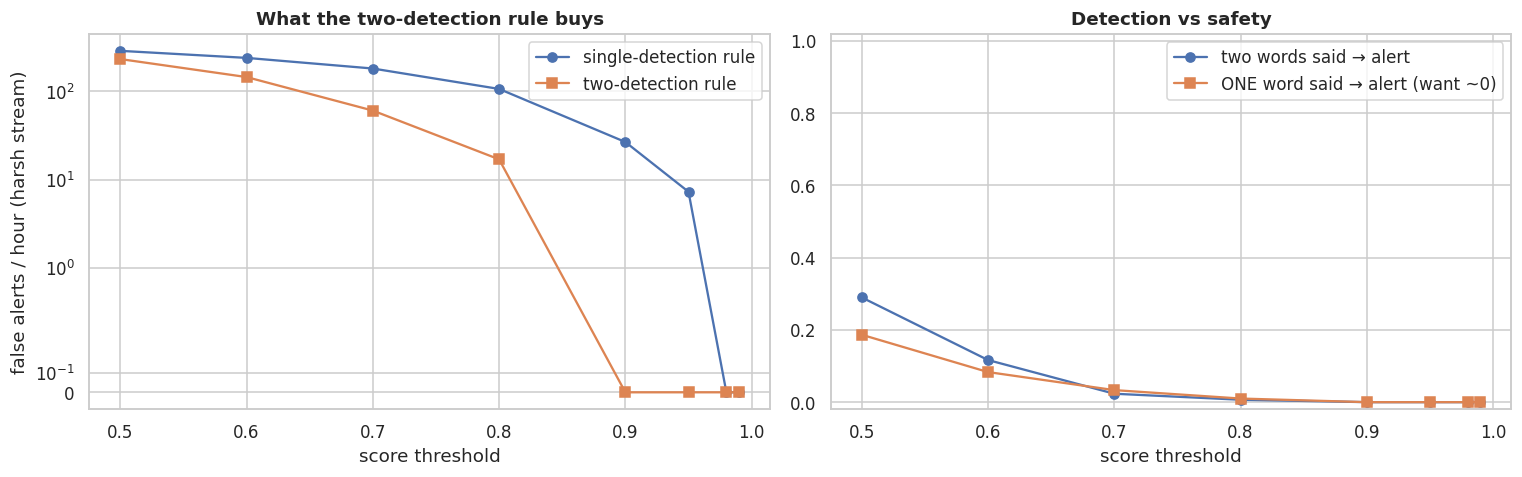

Chosen operating threshold: 0.5  (lowest false-alert rate that still triggers ≥ 80 % of two-word trials).  Override THRESHOLD here if you prefer a different trade-off.


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(SIM.threshold, SIM.false_alerts_per_hr_single_rule, "o-", label="single-detection rule")
ax[0].plot(SIM.threshold, SIM.false_alerts_per_hr_pair_rule, "s-", label="two-detection rule")
ax[0].set_yscale("symlog", linthresh=0.5); ax[0].set_xlabel("score threshold"); ax[0].set_ylabel("false alerts / hour (harsh stream)"); ax[0].set_title("What the two-detection rule buys"); ax[0].legend()
ax[1].plot(SIM.threshold, SIM.trigger_rate_two_words, "o-", label="two words said → alert")
ax[1].plot(SIM.threshold, SIM.alert_rate_one_word_pair_rule, "s-", label="ONE word said → alert (want ~0)")
ax[1].set_ylim(-0.02, 1.02); ax[1].set_xlabel("score threshold"); ax[1].set_title("Detection vs safety"); ax[1].legend()
plt.tight_layout(); plt.savefig(RES / "streaming_simulation.png", dpi=150); plt.show()

ok = SIM[SIM.trigger_rate_two_words >= 0.80]
THRESHOLD = float((ok.sort_values(["false_alerts_per_hr_pair_rule", "threshold"]).iloc[0] if len(ok) else SIM.sort_values("trigger_rate_two_words", ascending=False).iloc[0]).threshold)
print(f"Chosen operating threshold: {THRESHOLD}  (lowest false-alert rate that still triggers ≥ 80 % of two-word trials).  Override THRESHOLD here if you prefer a different trade-off.")

In [ ]:
# ---- error analysis ----
errs = meta[meta.p != meta.y].copy(); errs["conf"] = P_test[errs.index, errs.p.values]
print(f"{len(errs)} test errors out of {len(meta)}")
conf_pairs = errs.groupby([errs.y.map(dict(enumerate(LABELS))), errs.p.map(dict(enumerate(LABELS)))]).size().sort_values(ascending=False).head(10)
print("most common confusions (true, predicted):\n", conf_pairs.to_string())
from IPython.display import Audio, display as _d
for _, r in errs.sort_values("conf", ascending=False).head(6).iterrows():
    print(f"true={LABELS[r.y]} predicted={LABELS[r.p]} (p={r.conf:.2f}) lang={r.lang} src={r.source} word={r.word}")
    _d(Audio(str(CLIPS / r.file)))

498 test errors out of 1647
most common confusions (true, predicted):
 y        p      
unknown  msaada     136
         help        93
         police      92
         polisi      90
noise    help        37
         unknown     17
msaada   unknown      8
noise    msaada       7
polisi   police       4
help     unknown      3
true=unknown predicted=polisi (p=0.96) lang=sw src=cv27 word=ofsi


true=unknown predicted=police (p=0.96) lang=en src=mswc word=aberration


true=unknown predicted=police (p=0.94) lang=en src=mswc word=aces


true=unknown predicted=help (p=0.93) lang=en src=mswc word=adopt


true=noise predicted=help (p=0.92) lang=env src=esc50 word=frog


true=unknown predicted=help (p=0.92) lang=en src=mswc word=abundant


## 10. Quantisation and export (TinyML)
The float model is converted to **INT8 TensorFlow Lite**, re-evaluated (quantisation can cost accuracy), and exported as C headers: model bytes, feature-normalisation constants, labels, the chosen threshold, and the trigger logic.

> ⚠️ **Feature parity:** this exported model expects the *exact* log-mel front-end used here (STFT 480/320/512, 40 mel bands, `log(x + 1e-6)`, then `(x - MU) / SD`). Porting that front-end to the ESP32 is real work. The **Edge Impulse track (section 11)** avoids this because Edge Impulse generates the DSP and model together as one C++ library.

In [ ]:
def representative_data():
    idx = np.random.RandomState(0).choice(len(D["train"]["X"]), min(400, len(D["train"]["X"])), replace=False)
    for i in idx:
        f = (logmel_tf(tf.cast(D["train"]["X"][i], tf.float32) / 32768.0).numpy() - MU) / SD
        yield [f[None, ..., None].astype(np.float32)]

def to_int8_tflite(model):
    try:
        conv = tf.lite.TFLiteConverter.from_keras_model(model)
    except Exception:
        model.export(str(RES / "saved_model")); conv = tf.lite.TFLiteConverter.from_saved_model(str(RES / "saved_model"))
    conv.optimizations = [tf.lite.Optimize.DEFAULT]; conv.representative_dataset = representative_data
    conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    conv.inference_input_type = tf.int8; conv.inference_output_type = tf.int8
    return conv.convert()

TFLITE = to_int8_tflite(MODEL)
(RES / "safeguard_kws_int8.tflite").write_bytes(TFLITE)

interp = tf.lite.Interpreter(model_content=TFLITE); interp.allocate_tensors()
inp, outp = interp.get_input_details()[0], interp.get_output_details()[0]
(si, zi), (so, zo) = inp["quantization"], outp["quantization"]

def predict_int8(split):
    F = (compute_feats(D[split]["X"]) - MU) / SD; out = np.zeros((len(F), NUM_CLASSES), np.float32)
    for i, f in enumerate(F):
        q = np.clip(np.round(f[None, ..., None] / si + zi), -128, 127).astype(np.int8)
        interp.set_tensor(inp["index"], q); interp.invoke()
        out[i] = (interp.get_tensor(outp["index"])[0].astype(np.float32) - zo) * so
    return out

P_int8 = predict_int8("test")
for s in ["val", "test"]:
    log_result("DS-CNN (INT8 TFLite)", s, D[s]["y"], (P_int8 if s == "test" else predict_int8("val")).argmax(1), params=MODEL.count_params())

# rough tensor-arena estimate: largest (input + output) activation pair, INT8 bytes
shapes = [int(np.prod(l.output.shape[1:])) for l in MODEL.layers if hasattr(l, "output") and l.output is not None]
arena_kb = max(a + b for a, b in zip(shapes[:-1], shapes[1:])) / 1024
print(f"INT8 model size: {len(TFLITE) / 1024:.1f} KB | parameters: {MODEL.count_params():,} | rough arena estimate: ~{arena_kb:.0f} KB (measure on device)")
display(pd.DataFrame(RESULTS).query("split == 'test'")[["model", "macro_f1", "kw_recall", "false_accept"]].round(3))

Saved artifact at '/tmp/tmpkl8d2zg8'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 49, 40, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  139501682274768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139501682277264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139501682274576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139501682277456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139501682275344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139501682274960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139501682276688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139501682276496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139501682262480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139501682263632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139501682276880:

,model,macro_f1,kw_recall,false_accept
1,majority class,0.113,0.000,0.000
3,MFCC + LogReg,0.545,0.860,0.256
5,MFCC + RandomForest,0.412,0.189,0.003
7,DS-CNN (float32),0.507,0.878,0.310
9,DS-CNN (INT8 TFLite),0.506,0.884,0.318


In [ ]:
# ---- Does it fit the ESP32-C3? (budget from the config cell) ----
cost = model_cost(MODEL)
fit = pd.DataFrame([
    dict(item="model in flash (INT8 .tflite)", value=len(TFLITE) / 1024, limit=MCU["flash_model_kb"], unit="KB"),
    dict(item="tensor arena (rough)",          value=cost["arena_kb"],    limit=MCU["arena_kb"],      unit="KB"),
    dict(item="parameters",                    value=cost["params"],      limit=MCU["params_max"],    unit=""),
    dict(item="MACs per inference",            value=cost["macs"] / 1e6,  limit=MCU["macs_max"] / 1e6, unit="million"),
    dict(item="estimated inference time",      value=cost["est_ms"],      limit=MCU["latency_ms_max"], unit="ms (ASSUMED speed)"),
])
fit["fits"] = fit.value <= fit.limit
display(fit.round(2))
print("All within budget:" , bool(fit.fits.all()))
print("The latency row uses an ASSUMED 10 M MAC/s. Time one real inference on your C3 (esp_timer_get_time around the invoke) and update MCU['macs_per_sec'].")

,item,value,limit,unit,fits
0,model in flash (INT8 .tflite),19.43,200.0,KB,True
1,tensor arena (rough),8.12,64.0,KB,True
2,parameters,4110.00,40000.0,,True
3,MACs per inference,0.45,3.0,million,True
4,estimated inference time,45.33,150.0,ms (ASSUMED speed),True


All within budget: True
The latency row uses an ASSUMED 10 M MAC/s. Time one real inference on your C3 (esp_timer_get_time around the invoke) and update MCU['macs_per_sec'].


In [ ]:
def bytes_to_c(data, name="g_safeguard_kws_model"):
    lines = [f"alignas(16) const unsigned char {name}[] = {{"]
    for i in range(0, len(data), 12):
        lines.append("  " + ", ".join(f"0x{b:02x}" for b in data[i:i + 12]) + ",")
    lines += ["};", f"const unsigned int {name}_len = {len(data)};"]
    return "\n".join(lines)

EXPORT = RES / "firmware"; EXPORT.mkdir(exist_ok=True)
(EXPORT / "safeguard_kws_model.h").write_text("#pragma once\n// INT8 DS-CNN keyword spotter: classes " + ", ".join(f"{i}={l}" for i, l in enumerate(LABELS)) + "\n" + bytes_to_c(TFLITE) + "\n")

(EXPORT / "kws_config.h").write_text(f"""#pragma once
// Auto-generated. Front-end must match training exactly.
#define KWS_SAMPLE_RATE      {SR}
#define KWS_WINDOW_SAMPLES   {WIN}
#define KWS_FRAME_LEN        {FRAME}
#define KWS_FRAME_STEP       {HOP}
#define KWS_FFT_LEN          {NFFT}
#define KWS_NUM_MELS         {N_MELS}
#define KWS_NUM_FRAMES       {N_FRAMES}
#define KWS_MEL_FMIN_HZ      80.0f
#define KWS_MEL_FMAX_HZ      7600.0f
#define KWS_LOG_EPS          1e-6f
#define KWS_FEAT_MEAN        {MU:.6f}f
#define KWS_FEAT_STD         {SD:.6f}f
#define KWS_INPUT_SCALE      {si:.8f}f
#define KWS_INPUT_ZERO_POINT {int(zi)}
#define KWS_OUTPUT_SCALE     {so:.8f}f
#define KWS_OUTPUT_ZERO_POINT {int(zo)}
#define KWS_NUM_CLASSES      {NUM_CLASSES}
#define KWS_THRESHOLD        {THRESHOLD}f
#define KWS_HOP_MS           {int(HOP_S * 1000)}
#define KWS_PAIR_WINDOW_MS   {int(PAIR_WINDOW_S * 1000)}
#define KWS_REFRACTORY_MS    {int(REFRACTORY_S * 1000)}
#define KWS_COOLDOWN_MS      {int(COOLDOWN_S * 1000)}
static const char* KWS_LABELS[KWS_NUM_CLASSES] = {{{", ".join(f'"{l}"' for l in LABELS)}}};
// class ids that are keywords: {", ".join(f"{LABEL2ID[t]}={t}" for t in TARGETS)}
""")

(EXPORT / "trigger_logic.h").write_text(r"""#pragma once
#include <stdint.h>
// Two-detection trigger: call update() once per inference with the best keyword score (max over keyword classes).
// Returns true exactly when an alert should START (then run your cancel window before sending anything).
struct KwsTrigger {
  float threshold; int64_t pair_window_ms, refractory_ms, cooldown_ms;
  int64_t last_det_ms = -1000000000LL, prev_event_ms = -1000000000LL, last_alert_ms = -1000000000LL;
  KwsTrigger(float thr, int64_t pair, int64_t refr, int64_t cool)
      : threshold(thr), pair_window_ms(pair), refractory_ms(refr), cooldown_ms(cool) {}
  bool update(int64_t now_ms, float best_keyword_score) {
    if (best_keyword_score < threshold) return false;
    bool new_event = (now_ms - last_det_ms) >= refractory_ms;
    last_det_ms = now_ms;
    if (!new_event) return false;
    bool alert = (now_ms - prev_event_ms) <= pair_window_ms && (now_ms - last_alert_ms) >= cooldown_ms;
    prev_event_ms = now_ms;
    if (alert) last_alert_ms = now_ms;
    return alert;
  }
};
""")
print("Wrote:", *[p.name for p in EXPORT.iterdir()], sep="\n  ")

Wrote:
  safeguard_kws_model.h
  kws_config.h
  trigger_logic.h


## 11. Edge Impulse track (recommended for deployment)
Edge Impulse gives you the whole embedded chain in one tool: audio DSP (MFE/MFCC), model training with its own tuner, on-device RAM/flash/latency estimates, and a **C++ library** that includes the feature extraction, so there is no front-end porting. This notebook's job is to hand it **exactly the same clean, speaker-disjoint data** used above, so the two tracks are directly comparable.

**Step A (below):** upload with the official ingestion API. Train split (+ val split, see flag) → *training*, test split → *testing*. Edge Impulse makes its own validation split from the training data, so its validation score may be slightly optimistic (same speakers can fall on both sides); the **testing** set stays clean.

**Step B (in Studio, ~10 min):**
1. *Create impulse*: time-series input, **window size 1000 ms**, window increase 500 ms (clips are exactly 1 s) → **Audio (MFE)** block (try **MFCC** too) → **Classification** block.
2. *Generate features*, check the feature explorer: keyword classes should form visible clusters.
3. *Classifier*: start from the default 1D/2D CNN, then try the **EON Tuner** (Edge Impulse's automatic search over DSP + model settings: the counterpart of section 7) if your plan includes it.
4. *Model testing*: classify the test set; compare **accuracy / per-class F1** with section 9.
5. *Deployment*: C++ library (ESP-IDF) or Arduino library, **Quantized (int8)**, EON-compiled. Check the reported RAM/flash/latency for your ESP32-C3.
6. In firmware, feed each 250 ms-stride result into `trigger_logic.h` (above), then run the cancel window.

In [ ]:
UPLOAD_TO_EI = False                    # set True when your EI_API_KEY secret is ready
EI_INCLUDE_VAL_IN_TRAINING = True       # val speakers become extra training data on the EI side (test stays untouched)

def ei_upload(batch=100):
    import requests
    key = get_secret("EI_API_KEY", prompt=True)
    plan = []
    for split, cat in [("train", "training"), ("val", "training" if EI_INCLUDE_VAL_IN_TRAINING else None), ("test", "testing")]:
        if cat is None: continue
        for lab, grp in M[M.split == split].groupby("label"):
            plan.append((cat, lab, list(grp.file)))
    sent, failed = Counter(), []
    for cat, lab, files in plan:
        for i in tqdm(range(0, len(files), batch), desc=f"{cat}/{lab}", leave=False):
            chunk, handles = files[i:i + batch], []
            try:
                multipart = []
                for f in chunk:
                    h = open(CLIPS / f, "rb"); handles.append(h)
                    multipart.append(("data", (f"{lab}.{Path(f).stem}.wav", h, "audio/wav")))
                r = requests.post(f"https://ingestion.edgeimpulse.com/api/{cat}/files",
                                  headers={"x-api-key": key, "x-label": lab, "x-disallow-duplicates": "1"}, files=multipart, timeout=600)
                if r.status_code == 200: sent[(cat, lab)] += len(chunk)
                else: failed.append((cat, lab, r.status_code, r.text[:200]))
            finally:
                for h in handles: h.close()
    print("uploaded:", dict(sent)); print("failed batches:", failed[:5] if failed else "none")
    (RES / "ei_upload_report.json").write_text(json.dumps({"sent": {f"{a}/{b}": n for (a, b), n in sent.items()}, "failed": failed}, indent=1))

if UPLOAD_TO_EI and not SMOKE_TEST: ei_upload()
else: print("Edge Impulse upload skipped (set UPLOAD_TO_EI = True after adding the EI_API_KEY secret).")

Edge Impulse upload skipped (set UPLOAD_TO_EI = True after adding the EI_API_KEY secret).


## 12. Summary, model card and artefacts

In [ ]:
R = pd.DataFrame(RESULTS)
summary = R[R.split == "test"][["model", "macro_f1", "acc", "kw_recall", "false_accept"]].round(3)
display(summary)
chosen = SIM[SIM.threshold == THRESHOLD].iloc[0]
card = f"""# SafeGuard KWS v2: model card
**Task:** bilingual emergency keyword spotting ({', '.join(TARGETS)}) + unknown + noise, 1 s windows @16 kHz.
**Data:** Common Voice 27 Swahili (forced-aligned words), MSWC English, ESC-50 noise. Speaker-disjoint train/val/test.
**Model:** DS-CNN, {MODEL.count_params():,} parameters, INT8 TFLite {len(TFLITE) / 1024:.1f} KB.
**Best hyper-parameters:** { {k: BEST_CFG[k] for k in ['lr', 'width', 'blocks', 'dropout', 'ls', 'batch', 'noise_p', 'wd']} }

## Test results (per-clip)
{summary.to_markdown(index=False)}

## Streaming simulation (threshold {THRESHOLD}, two-detection rule)
- Two-word trigger rate: {chosen.trigger_rate_two_words:.2f}
- One-word alert rate (safety property, want ~0): {chosen.alert_rate_one_word_pair_rule:.2f}
- False alerts/hour on a harsh continuous negative stream: {chosen.false_alerts_per_hr_pair_rule:.2f} ({neg_hours * 60:.1f} min of audio)

## Known limitations
- Training speech is read speech from phones/laptops, not shouted distress speech on the pendant microphone.
- Noise class comes from ESC-50 (no matatu / market recordings yet).
- Per-day false-alert rates cannot be claimed from minutes of audio; run a multi-hour real-environment test.
- Real-device recordings (`real/`) are the deciding evidence; the numbers above are an upper bound until they exist.
"""
(RES / "model_card.md").write_text(card)
R.to_csv(RES / "all_results.csv", index=False)
json.dump(dict(labels=LABELS, threshold=THRESHOLD, best_cfg={k: (float(v) if isinstance(v, (np.floating,)) else v) for k, v in BEST_CFG.items()},
               mu=MU, sd=SD, params=int(MODEL.count_params()), tflite_kb=len(TFLITE) / 1024), open(RES / "summary.json", "w"), indent=1, default=str)
shutil.make_archive(str(ROOT / "kws_v2_artifacts"), "zip", RES)
print("Saved model card, results, firmware headers and plots in", RES, "\nZip:", ROOT / "kws_v2_artifacts.zip")
try:
    from google.colab import files; files.download(str(ROOT / "kws_v2_artifacts.zip"))
except Exception:
    pass

,model,macro_f1,acc,kw_recall,false_accept
1,majority class,0.113,0.513,0.000,0.000
3,MFCC + LogReg,0.545,0.748,0.860,0.256
5,MFCC + RandomForest,0.412,0.891,0.189,0.003
7,DS-CNN (float32),0.507,0.698,0.878,0.310
9,DS-CNN (INT8 TFLite),0.506,0.692,0.884,0.318


Saved model card, results, firmware headers and plots in /content/drive/MyDrive/SafeGuard-STT/kws_v2/results 
Zip: /content/drive/MyDrive/SafeGuard-STT/kws_v2/kws_v2_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## What to do next
1. **Run it for real** (`SMOKE_TEST = False`). Look at EDA first; fix any red flags before reading model metrics.
2. **Record real people on the pendant mic:** 10-20 friends × each of the 4 words × 5-10 repetitions, plus 5 minutes of each person talking normally and some real background (street, matatu, market). Put them in `real/`; re-run from section 2; the `real` block in section 9 is your honest result.
3. **Upload to Edge Impulse** (section 11), compare with this notebook's model on the same test set, deploy whichever wins on the C3.
4. **Long false-alert test:** wear the device for hours/days with alerts disabled and log detections. Tune the threshold, pair window and cancel window from that data.
5. Ask Kenyan Swahili speakers what they actually shout in an emergency; add those words (`wezi`, `moto`, …) as classes if they matter.